# Analyse des ajustements d'inventaire (`inventory_adjustments`) : exploration, patterns et anomalies

**Contexte.** Ce notebook applique à la table `inventory_adjustments.csv` (corrections manuelles de stock : site, date, catégorie, quantité ajoutée ou retirée, motif, rôle de l'approbateur, statut, références éventuelles à un reçu ou à une expédition) **la même démarche que les notebooks des expéditions, des achats et de l'inventaire de fin de mois**. L'objectif est de comprendre la structure des données, puis de repérer des **comportements inhabituels** : combinaisons rares mais cohérentes (*patterns*) et lignes atypiques.

**Particularités de cette table.** Elle ne compte que **140 lignes** et ses seules variables numériques (quantité, date) sont peu informatives : les anomalies y sont surtout **logiques** (références incohérentes, statuts, motifs à sens unique) et se révèlent par **recoupement** avec les tables des expéditions, des reçus et de l'inventaire. On construit donc dès le nettoyage des variables de contrôle (cohérence des références, fin de mois, sens de l'ajustement).


---
## 0. Configuration

### 0.1 Imports et modules utilitaires

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

project_root = next(
	(path for path in [Path.cwd(), *Path.cwd().parents]
	 if (path / "utils").is_dir()),
	Path.cwd(),
)
if str(project_root) not in sys.path:
	sys.path.insert(0, str(project_root))

from utils.clean_csv import clean_csv
from utils.variable_analysis import analyser_variables, tracer_histogrammes
from utils.correlation_matrices import tracer_matrices
from utils.pattern_detection import lire_csv, enrichir, detecter_patterns, profiler_groupe, masque_itemset
from utils.anomaly_detection import detecter_anomalies


**Rapport.** Mêmes modules `utils` que pour les autres tables : `clean_csv` (nettoyage), `variable_analysis` (histogrammes et statistiques), `correlation_matrices` (Spearman / V de Cramér), `pattern_detection` (itemsets fréquents) et `anomaly_detection` (IQR, clustering, ABOD). Le dossier racine du projet est ajouté automatiquement au `sys.path`.

---
## 1. Chargement, nettoyage et variables dérivées

### 1.1 Lecture et nettoyage du fichier


In [2]:
# 1) Quantités écrites avec leur unité ("-2.9 case") : on garde le nombre
brut = pd.read_csv("../data/logistics/inventory_adjustments.csv")
brut["adjustment_quantity"] = brut["adjustment_quantity"].astype(str).str.extract(r"^\s*(-?[\d.,]+)")[0]

# 2) Nettoyage générique (réglage par défaut : on vérifie au 1.2 qu'il ne supprime rien d'utile)
adj, rapport = clean_csv(brut)

Avant nettoyage : (140, 11)
Nombre de doublons sur ['adjustment_number'] : 0
Après suppression des doublons : (140, 11)
Dates normalisées : {'adjustment_date': 'datetime64[ns]'}
adjustment_reason : 12 -> 10 modalités distinctes

Forme finale : (140, 11)
Valeurs manquantes après traitement :
Aucune


### 1.2 Contrôles sur le fichier brut

*On liste les irrégularités de format détectées dans le fichier brut et on vérifie que le nettoyage n'a supprimé aucune valeur par un traitement de « valeurs aberrantes » (piège rencontré sur les achats et l'inventaire).*

In [3]:
# Contrôles sur le fichier brut : formats hétérogènes et valeurs vides
fichier = pd.read_csv("../data/logistics/inventory_adjustments.csv")
q_texte = fichier.adjustment_quantity[pd.to_numeric(fichier.adjustment_quantity, errors="coerce").isna()]
dates_non_iso = fichier.adjustment_date[~fichier.adjustment_date.str.match(r"^\d{4}-\d{2}-\d{2}$")]
motifs = fichier.adjustment_reason
print("Quantités non numériques  :", q_texte.tolist())
print("Dates hors format ISO     :", dates_non_iso.tolist())
print("Motifs avec variante de casse :", motifs[motifs != motifs.str.lower()].tolist())
print("\nValeurs vides (brut) :", fichier.isna().sum()[lambda s: s > 0].to_dict())
print("Valeurs aberrantes remplacées par le nettoyage :", rapport["outliers_traites_comme_manquants"] or "aucune")

Quantités non numériques  : ['-2.9 case']
Dates hors format ISO     : ['12/11/2023', '21-Mar-2024']
Motifs avec variante de casse : ['Transfer Posting Correction', 'TRANSFER POSTING CORRECTION']

Valeurs vides (brut) : {'approved_by_role': 1, 'related_receipt_number': 117, 'related_shipment_number': 103}
Valeurs aberrantes remplacées par le nettoyage : aucune


### Rapport d'analyse — nettoyage

**Résultats**
- La table compte **140 lignes et 11 colonnes** ; aucun doublon (ni sur `adjustment_number`, ni sur la ligne entière).
- `adjustment_reason` passe de **12 à 10 modalités** : `Transfer Posting Correction` et `TRANSFER POSTING CORRECTION` étaient comptés à part.
- **Une quantité** (`"-2.9 case"`) est récupérée par le prétraitement. **Deux dates** sont dans un autre format que le format ISO (`12/11/2023` et `21-Mar-2024`) ; le nettoyage les convertit (la première en 12 novembre 2023, ce que confirme l'ordre des numéros d'ajustement).
- **Aucune valeur aberrante n'est remplacée** par le nettoyage : contrairement aux achats et à l'inventaire, le réglage par défaut est ici sans danger (les quantités vont de −7,91 à +7,87 de façon symétrique). Il n'y a donc pas lieu de le désactiver.


### 1.3 Variables dérivées : sens, fin de mois et cohérence des références



In [4]:
# --- Variables dérivées simples
adj["sens"] = np.where(adj.adjustment_quantity < 0, "retrait", "ajout")
adj["fin_de_mois"] = np.where(adj.adjustment_date.dt.is_month_end, "oui", "non")
adj["jour_du_mois"] = adj.adjustment_date.dt.day
adj["annee"] = adj.adjustment_date.dt.year.astype(str)
adj["a_recu"] = np.where(adj.related_receipt_number != "unknown", "oui", "non")
adj["a_expedition"] = np.where(adj.related_shipment_number != "unknown", "oui", "non")

# --- Cohérence des références (jointures avec goods_receipts et shipments)
gr = pd.read_csv("../data/logistics/goods_receipts.csv")
gr["receipt_date"] = pd.to_datetime(gr.receipt_date, format="mixed", errors="coerce")
sh, _ = clean_csv("../data/logistics/shipments.csv", verbose=False)
sh["dispatch_dt"] = pd.to_datetime(sh.dispatch_time, format="mixed")

r = adj.merge(gr[["receipt_number", "receipt_date", "receiving_facility_code"]],
              left_on="related_receipt_number", right_on="receipt_number", how="left")
s = adj.merge(sh[["shipment_number", "dispatch_dt", "origin_facility_code", "destination_facility_code",
                  "item_category"]].rename(columns={"item_category": "cat_exp"}),
              left_on="related_shipment_number", right_on="shipment_number", how="left")
ok_recu = (r.facility_code == r.receiving_facility_code) & (r.adjustment_date >= r.receipt_date)
ok_exp = (((s.facility_code == s.origin_facility_code) | (s.facility_code == s.destination_facility_code))
          & (s.item_category == s.cat_exp) & (s.adjustment_date >= s.dispatch_dt))
adj["jours_apres_recu"] = (r.adjustment_date - r.receipt_date).dt.days
adj["jours_apres_depart_exp"] = (s.adjustment_date - s.dispatch_dt).dt.days

lien = (adj.a_recu == "oui") | (adj.a_expedition == "oui")
coherent = (~(adj.a_recu == "oui") | ok_recu) & (~(adj.a_expedition == "oui") | ok_exp)
adj["coherence_lien"] = np.select([~lien, coherent], ["sans lien", "lien coherent"], "lien incoherent")

print("Lignes avec une référence à un reçu :", int((adj.a_recu == "oui").sum()),
      "| à une expédition :", int((adj.a_expedition == "oui").sum()))
print("Références introuvables : reçus", int(r.receipt_date.isna()[adj.a_recu == "oui"].sum()),
      "| expéditions", int(s.dispatch_dt.isna()[adj.a_expedition == "oui"].sum()))
print("\nCohérence des références (site, catégorie, date postérieure au document cité) :")
print(adj.coherence_lien.value_counts().to_string())
print("\nÂge des ajustements en attente (jours avant le 2025-06-30) :")
age = (pd.Timestamp("2025-06-30") - adj.loc[adj.adjustment_status == "pending_review", "adjustment_date"]).dt.days
print(age.describe().round(0).to_string())

Lignes avec une référence à un reçu : 23 | à une expédition : 37
Références introuvables : reçus 0 | expéditions 0

Cohérence des références (site, catégorie, date postérieure au document cité) :
coherence_lien
sans lien          85
lien incoherent    37
lien coherent      18

Âge des ajustements en attente (jours avant le 2025-06-30) :
count      25.0
mean     1467.0
std       887.0
min        54.0
25%       650.0
50%      1507.0
75%      2109.0
max      3449.0


### Rapport d'analyse — variables dérivées

**Résultats**
- **Les références existent toutes** : 23 ajustements citent un reçu et 37 une expédition, et aucune référence n'est introuvable dans `goods_receipts` ou `shipments`.
- **Mais la plupart sont incohérentes** : sur 140 lignes, **85 n'ont aucun lien (60,7 %)**, **37 ont un lien incohérent (26,4 %)** et seulement **18 un lien cohérent (12,9 %)**. Autrement dit, parmi les 55 ajustements qui citent un document, **37 (67 %)** le font avec un site, une catégorie ou une date qui ne correspond pas.
- **Ajustements en attente** : 25 lignes `pending_review`, d'âge médian **1 507 jours (plus de 4 ans)**, avec un minimum de 54 jours et un maximum de **3 449 jours (plus de 9 ans)**.


### 1.4 Aperçu des données

In [5]:
adj.head(5)

,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,unit,adjustment_reason,approved_by_role,related_receipt_number,related_shipment_number,adjustment_status,sens,fin_de_mois,jour_du_mois,annee,a_recu,a_expedition,jours_apres_recu,jours_apres_depart_exp,coherence_lien
0,ADJ-2014-00001,FCL-1007,2014-07-18,medical_consumables,-1.58,case,specialist programme issue,clinical stores manager,unknown,unknown,posted,retrait,non,18,2014,non,non,NaN,NaN,sans lien
1,ADJ-2015-00002,FCL-1007,2015-09-10,medical_consumables,-2.70,case,specialist programme issue,specialist programme administrator,unknown,unknown,posted,retrait,non,10,2015,non,non,NaN,NaN,sans lien
2,ADJ-2015-00003,FCL-1024,2015-10-30,monitoring_equipment,3.68,kit,late receipt posting,warehouse manager,RCV-2022-00361,unknown,posted,ajout,non,30,2015,oui,non,-2491.0,NaN,lien incoherent
3,ADJ-2016-00004,FCL-1007,2016-01-20,biological_sample,6.52,sealed_lot,late receipt posting,finance controller,unknown,unknown,pending_review,ajout,non,20,2016,non,non,NaN,NaN,sans lien
4,ADJ-2016-00005,FCL-1010,2016-02-18,medical_consumables,-2.43,case,procedure stock issue,quality manager,unknown,unknown,posted,retrait,non,18,2016,non,non,NaN,NaN,sans lien


**Rapport.** Les 11 colonnes d'origine se regroupent en : **identification** (`adjustment_number`, `facility_code`, `adjustment_date`), **marchandise** (`item_category`, `adjustment_quantity`, `unit`), **justification** (`adjustment_reason`, `approved_by_role`, `adjustment_status`) et **références** (`related_receipt_number`, `related_shipment_number`). Elles sont complétées par 9 variables dérivées (`sens`, `fin_de_mois`, `jour_du_mois`, `annee`, `a_recu`, `a_expedition`, `jours_apres_recu`, `jours_apres_depart_exp`, `coherence_lien`). Les premières lignes montrent des ajustements de faible ampleur (quelques unités) en retrait ou en ajout, validés par des rôles variés.

---
## 2. Analyse univariée

### 2.1 Histogrammes et statistiques descriptives



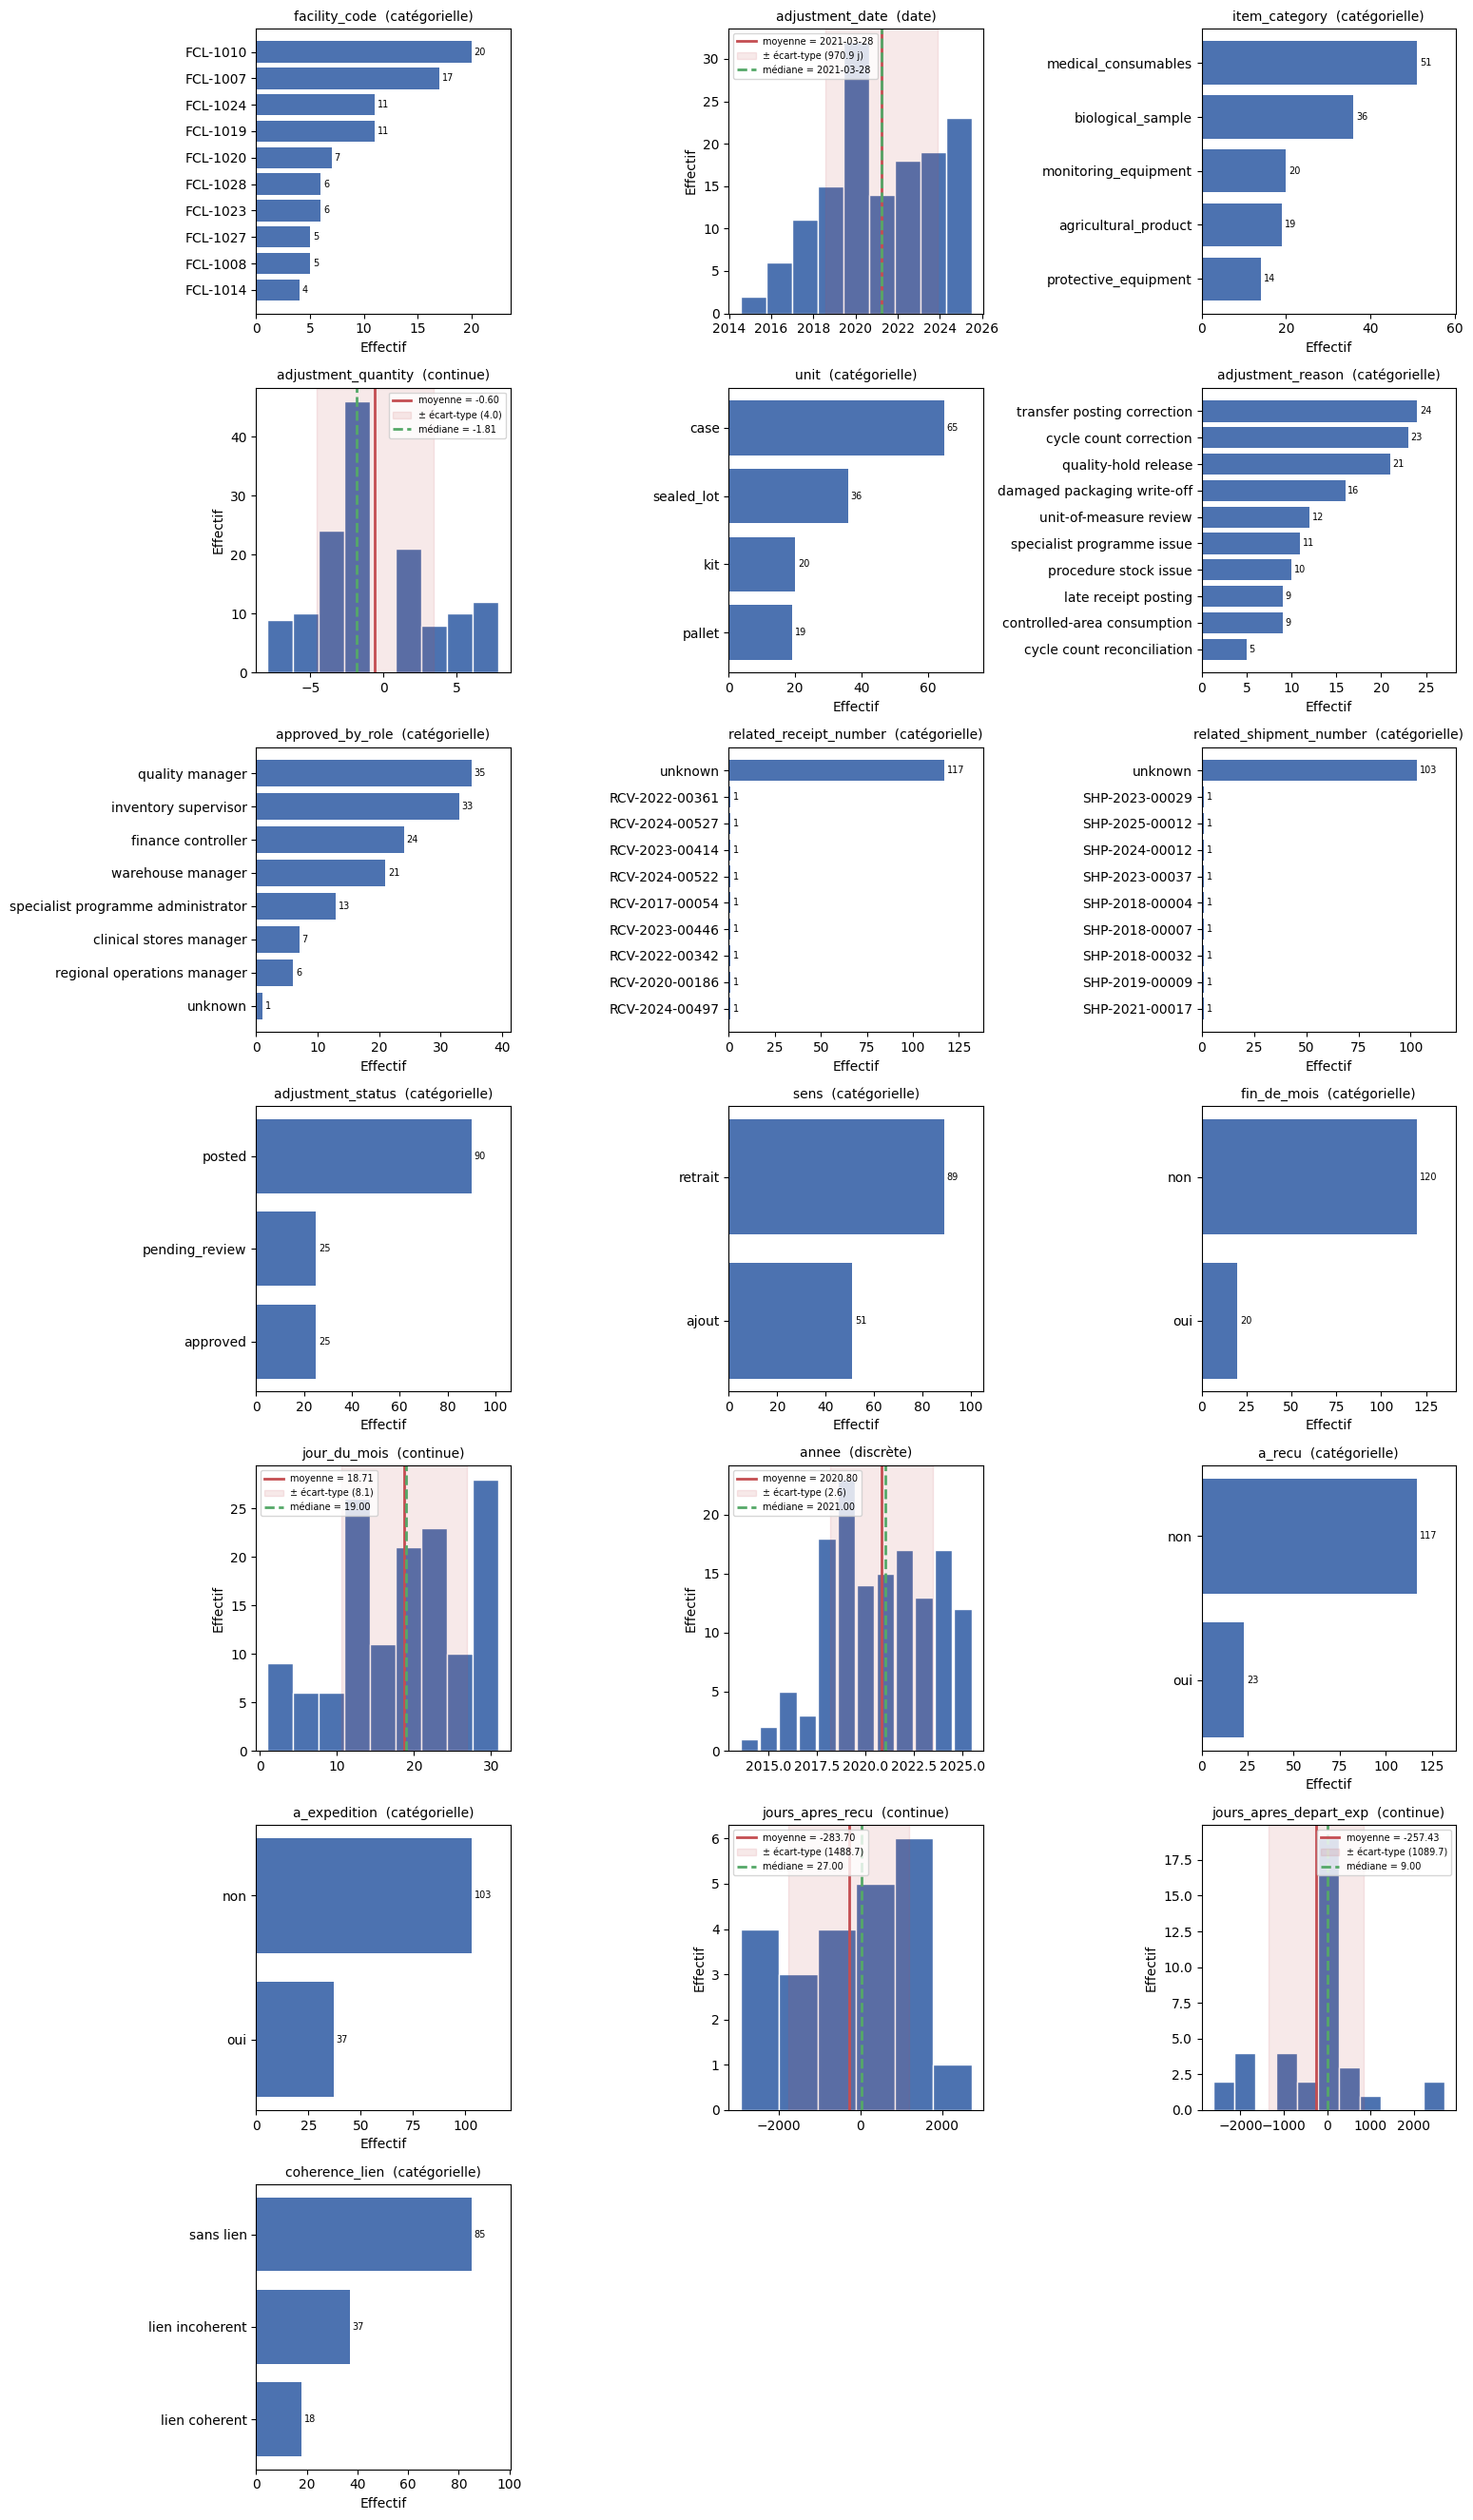


=== adjustment_number  [identifiant] ===
  140 valeurs toutes (quasi) différentes : non analysée.

=== facility_code  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 29)
  Mode : FCL-1010 (14.3 %)
               effectif     %
facility_code                
FCL-1010             20  14.3
FCL-1007             17  12.1
FCL-1024             11   7.9
FCL-1019             11   7.9
FCL-1020              7   5.0
FCL-1028              6   4.3
FCL-1023              6   4.3
FCL-1027              5   3.6
FCL-1008              5   3.6
FCL-1014              4   2.9
FCL-1029              4   2.9
FCL-1001              4   2.9
FCL-1003              4   2.9
FCL-1017              3   2.1
FCL-1009              3   2.1


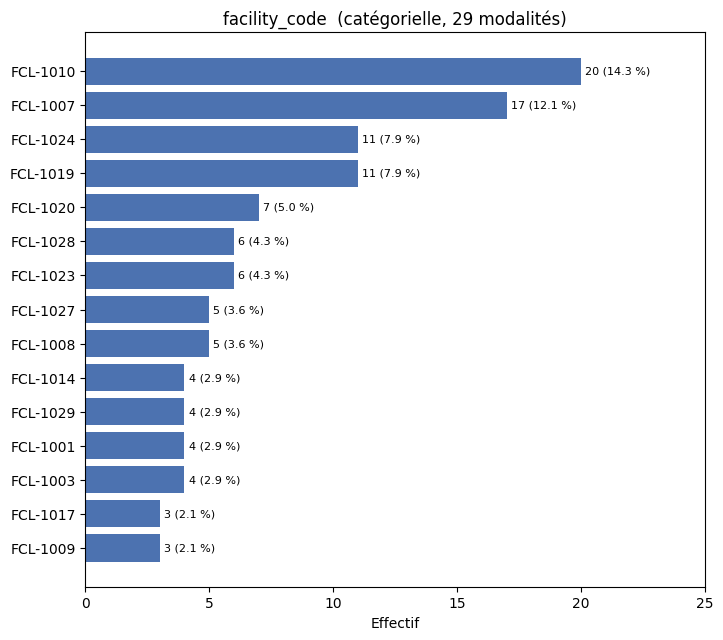


=== adjustment_date  [date] ===
  Effectif : 140  (manquants : 0, valeurs distinctes : 135)
  Moyenne ± écart-type : 2021-03-28 ± 970.9 jours
  Médiane [min ; Q1 - Q3 ; max] : 2021-03-28 [2014-07-18 ; 2019-07-30 - 2023-09-25 ; 2025-06-30]
  Asymétrie : -0.13


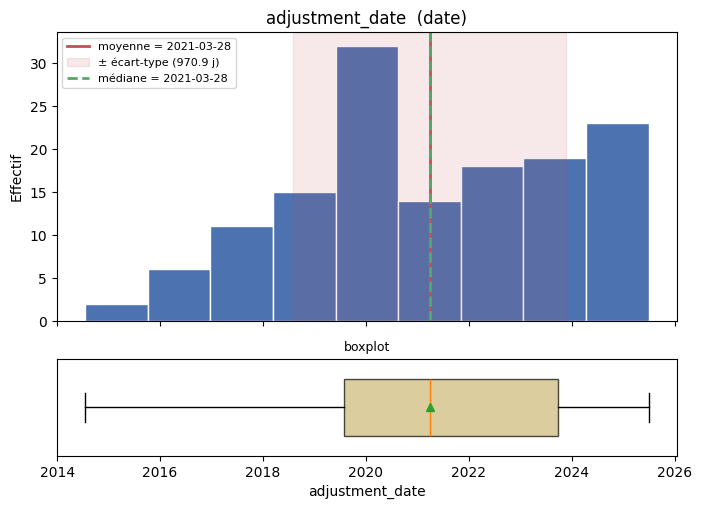


=== item_category  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 5)
  Mode : medical_consumables (36.4 %)
                      effectif     %
item_category                       
medical_consumables         51  36.4
biological_sample           36  25.7
monitoring_equipment        20  14.3
agricultural_product        19  13.6
protective_equipment        14  10.0


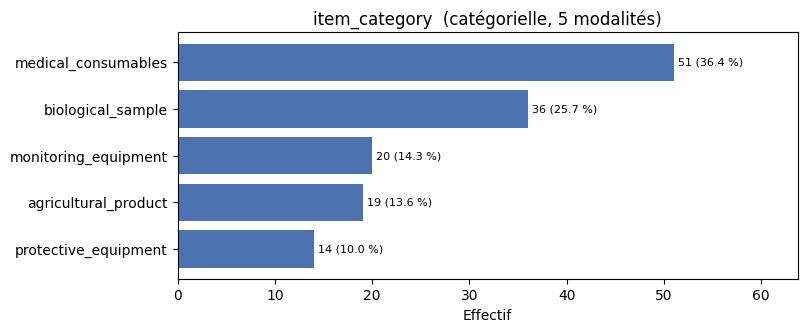


=== adjustment_quantity  [continue] ===
  Effectif : 140  (manquants : 0, valeurs distinctes : 127)
  Moyenne ± écart-type : -0.599 ± 3.995
  Médiane [min ; Q1 - Q3 ; max] : -1.805 [-7.910 ; -3.035 - 2.005 ; 7.870]
  Asymétrie : 0.51


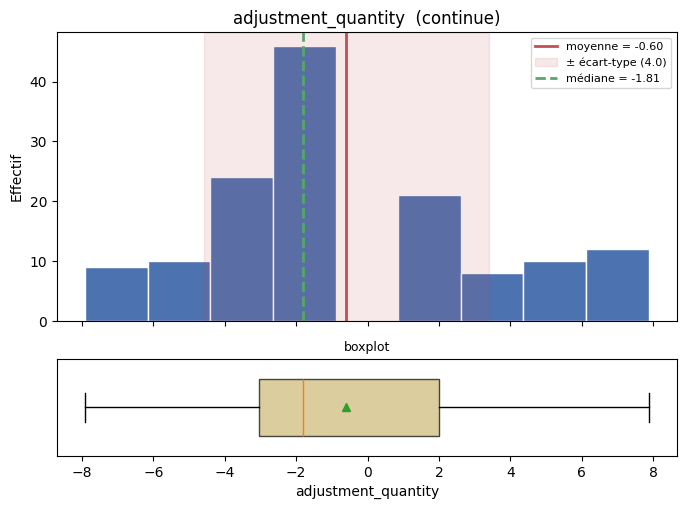


=== unit  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 4)
  Mode : case (46.4 %)
            effectif     %
unit                      
case              65  46.4
sealed_lot        36  25.7
kit               20  14.3
pallet            19  13.6


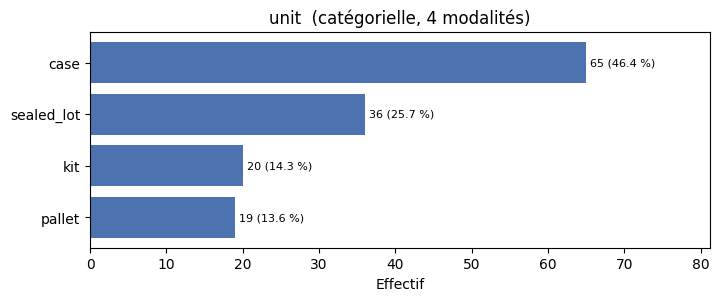


=== adjustment_reason  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 10)
  Mode : transfer posting correction (17.1 %)
                             effectif     %
adjustment_reason                          
transfer posting correction        24  17.1
cycle count correction             23  16.4
quality-hold release               21  15.0
damaged packaging write-off        16  11.4
unit-of-measure review             12   8.6
specialist programme issue         11   7.9
procedure stock issue              10   7.1
late receipt posting                9   6.4
controlled-area consumption         9   6.4
cycle count reconciliation          5   3.6


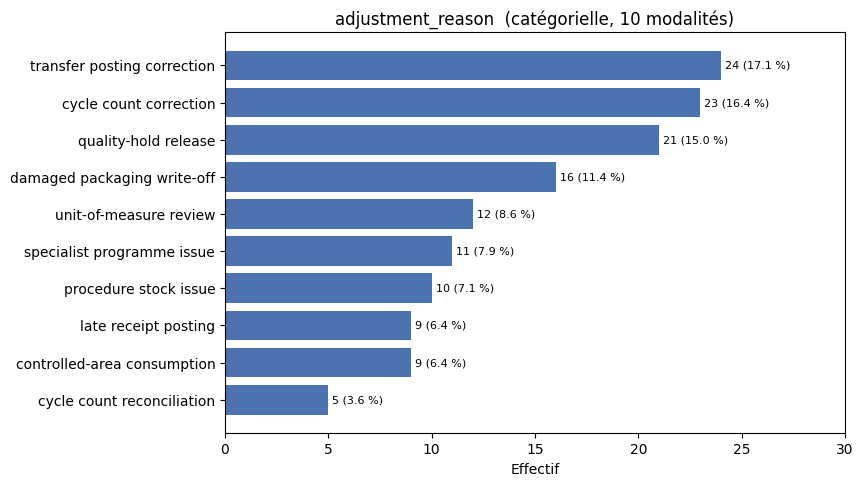


=== approved_by_role  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 8)
  Mode : quality manager (25.0 %)
                                    effectif     %
approved_by_role                                  
quality manager                           35  25.0
inventory supervisor                      33  23.6
finance controller                        24  17.1
warehouse manager                         21  15.0
specialist programme administrator        13   9.3
clinical stores manager                    7   5.0
regional operations manager                6   4.3
unknown                                    1   0.7


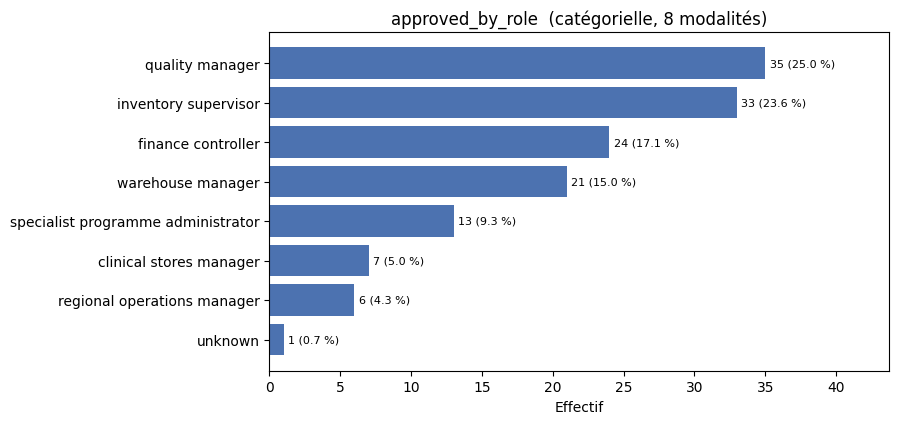


=== related_receipt_number  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 24)
  Mode : unknown (83.6 %)
                        effectif     %
related_receipt_number                
unknown                      117  83.6
RCV-2022-00361                 1   0.7
RCV-2024-00527                 1   0.7
RCV-2023-00414                 1   0.7
RCV-2024-00522                 1   0.7
RCV-2017-00054                 1   0.7
RCV-2023-00446                 1   0.7
RCV-2022-00342                 1   0.7
RCV-2020-00186                 1   0.7
RCV-2024-00497                 1   0.7
RCV-2022-00377                 1   0.7
RCV-2020-00220                 1   0.7
RCV-2018-00082                 1   0.7
RCV-2023-00475                 1   0.7
RCV-2019-00125                 1   0.7


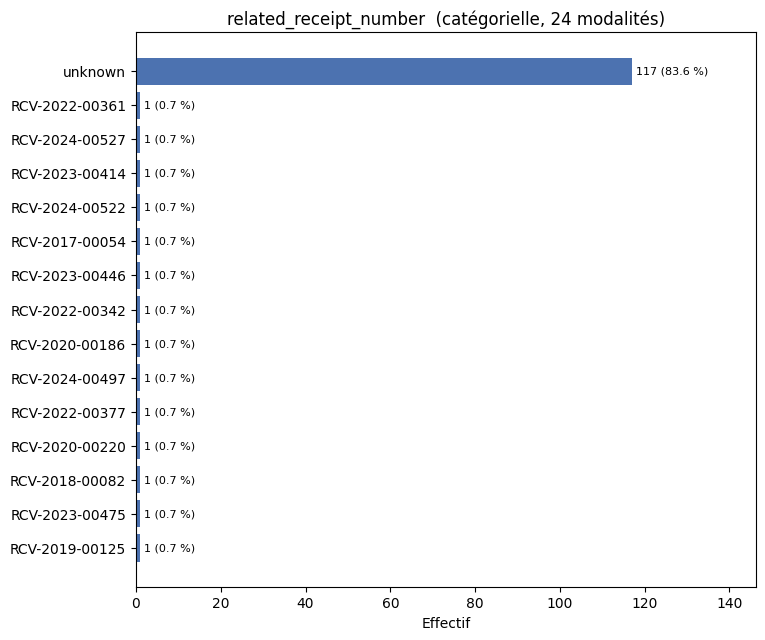


=== related_shipment_number  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 38)
  Mode : unknown (73.6 %)
                         effectif     %
related_shipment_number                
unknown                       103  73.6
SHP-2023-00029                  1   0.7
SHP-2025-00012                  1   0.7
SHP-2024-00012                  1   0.7
SHP-2023-00037                  1   0.7
SHP-2018-00004                  1   0.7
SHP-2018-00007                  1   0.7
SHP-2018-00032                  1   0.7
SHP-2019-00009                  1   0.7
SHP-2021-00017                  1   0.7
SHP-2024-00026                  1   0.7
SHP-2024-00027                  1   0.7
SHP-2019-00026                  1   0.7
SHP-2019-00041                  1   0.7
SHP-2023-00019                  1   0.7


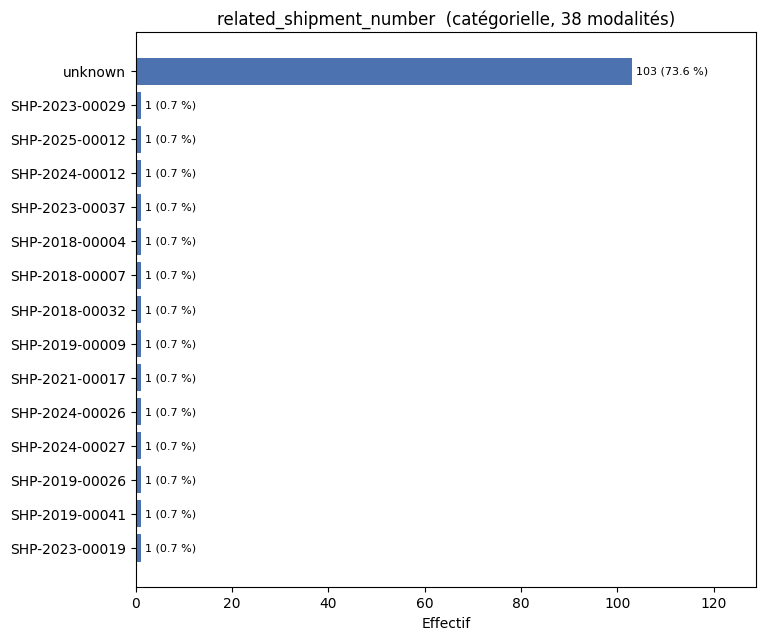


=== adjustment_status  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 3)
  Mode : posted (64.3 %)
                   effectif     %
adjustment_status                
posted                   90  64.3
pending_review           25  17.9
approved                 25  17.9


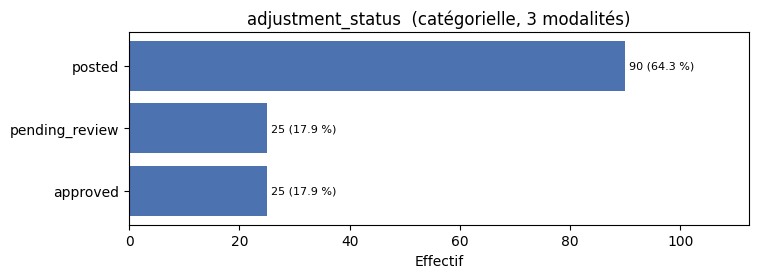


=== sens  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 2)
  Mode : retrait (63.6 %)
         effectif     %
sens                   
retrait        89  63.6
ajout          51  36.4


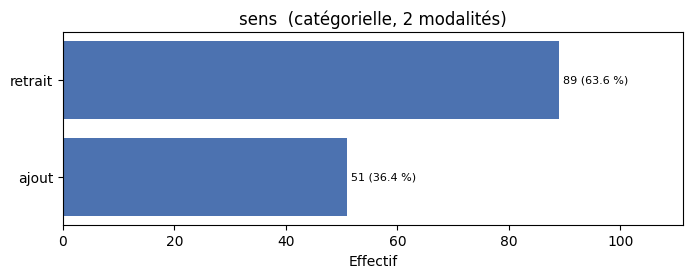


=== fin_de_mois  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 2)
  Mode : non (85.7 %)
             effectif     %
fin_de_mois                
non               120  85.7
oui                20  14.3


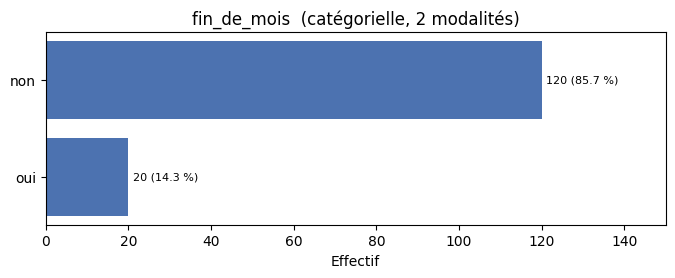


=== jour_du_mois  [continue] ===
  Effectif : 140  (manquants : 0, valeurs distinctes : 31)
  Moyenne ± écart-type : 18.714 ± 8.125
  Médiane [min ; Q1 - Q3 ; max] : 19.000 [1.000 ; 12.750 - 25.000 ; 31.000]
  Asymétrie : -0.25


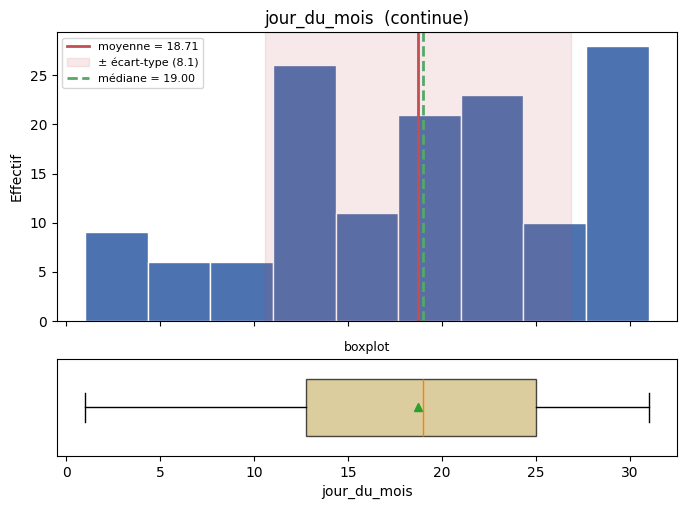


=== annee  [discrète] ===
  Effectif : 140  (manquants : 0, valeurs distinctes : 12)
  Moyenne ± écart-type : 2020.800 ± 2.642
  Médiane [min ; Q1 - Q3 ; max] : 2021.000 [2014.000 ; 2019.000 - 2023.000 ; 2025.000]
  Asymétrie : -0.14


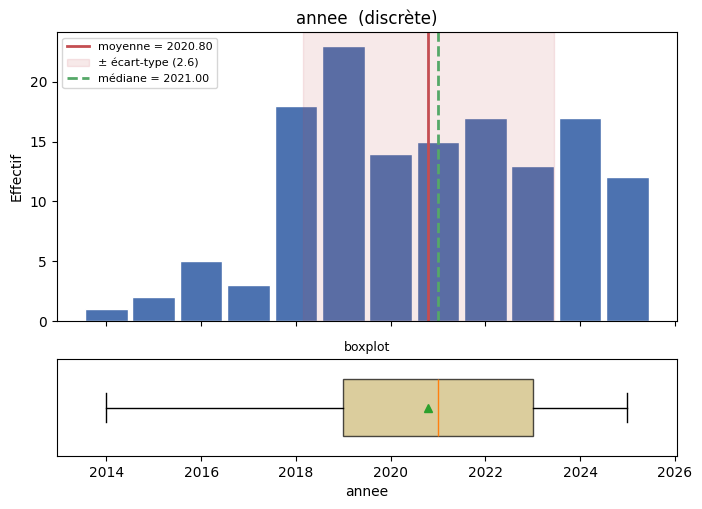


=== a_recu  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 2)
  Mode : non (83.6 %)
        effectif     %
a_recu                
non          117  83.6
oui           23  16.4


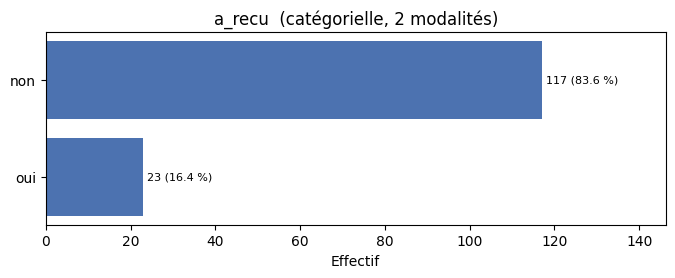


=== a_expedition  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 2)
  Mode : non (73.6 %)
              effectif     %
a_expedition                
non                103  73.6
oui                 37  26.4


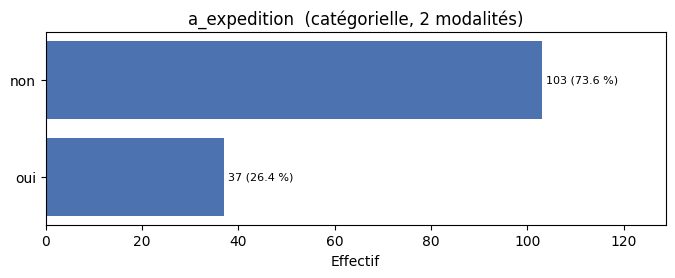


=== jours_apres_recu  [continue] ===
  Effectif : 23  (manquants : 117, valeurs distinctes : 23)
  Moyenne ± écart-type : -283.696 ± 1488.748
  Médiane [min ; Q1 - Q3 ; max] : 27.000 [-2944.000 ; -1473.500 - 861.500 ; 2724.000]
  Asymétrie : -0.07


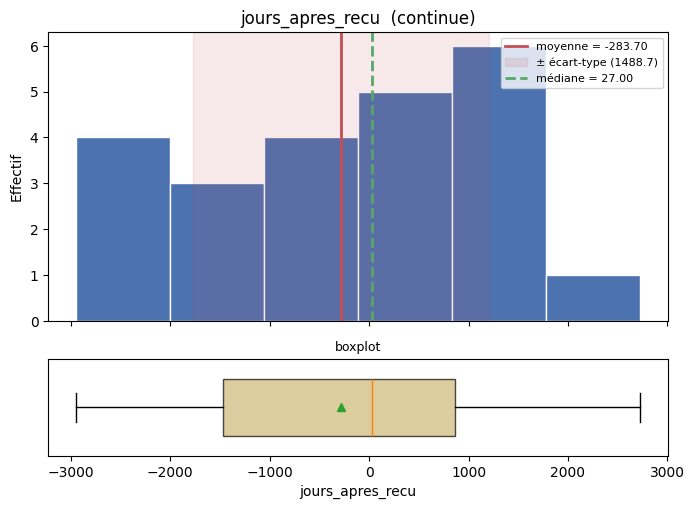


=== jours_apres_depart_exp  [continue] ===
  Effectif : 37  (manquants : 103, valeurs distinctes : 31)
  Moyenne ± écart-type : -257.432 ± 1089.725
  Médiane [min ; Q1 - Q3 ; max] : 9.000 [-2630.000 ; -847.000 - 19.000 ; 2701.000]
  Asymétrie : 0.20


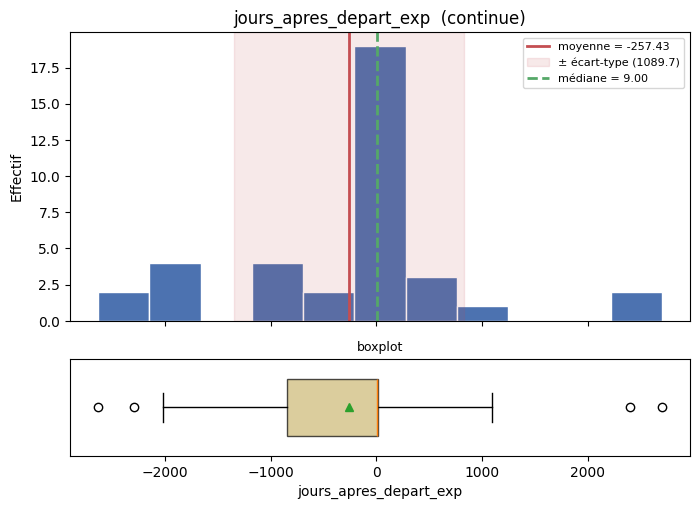


=== coherence_lien  [catégorielle] ===
  Effectif : 140  (manquants : 0, modalités : 3)
  Mode : sans lien (60.7 %)
                 effectif     %
coherence_lien                 
sans lien              85  60.7
lien incoherent        37  26.4
lien coherent          18  12.9


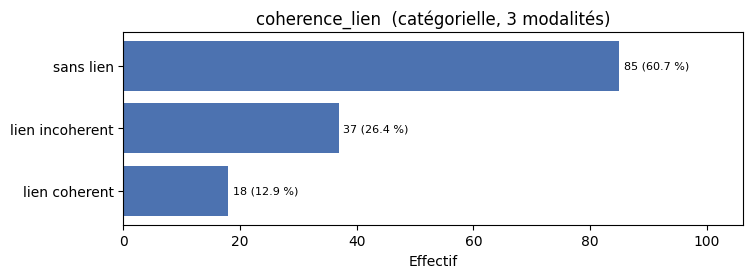

In [6]:
tracer_histogrammes(adj)
resume = analyser_variables(adj)

### Rapport d'analyse — analyse univariée

**1. Sites et dates**
- **29 sites** concernés, très inégalement : `FCL-1010` **14,3 %** (20 lignes) et `FCL-1007` **12,1 %** (17) en regroupent plus du quart ; viennent ensuite `FCL-1024` et `FCL-1019` (7,9 % chacun), `FCL-1020` (5,0 %), puis des sites à 4,3 % ou moins.
- Dates du **18 juillet 2014 au 30 juin 2025**, médiane au 28 mars 2021. L'activité est très faible avant 2018 (11 ajustements entre 2014 et 2017) puis régulière : 18 en 2018, **23 en 2019**, de 12 à 17 par an ensuite (calcul complémentaire).
- **20 ajustements (14,3 %) sont datés du dernier jour d'un mois.**

**2. Marchandise et quantité**
- Catégories : `medical_consumables` **36,4 %** (51), `biological_sample` 25,7 % (36), `monitoring_equipment` 14,3 % (20), `agricultural_product` 13,6 % (19) et `protective_equipment` 10,0 % (14). L'unité est déterminée par la catégorie.
- Quantité : moyenne **−0,60** ± 4,00, médiane −1,81, Q1-Q3 de −3,04 à 2,01, de **−7,91 à +7,87**, asymétrie 0,51. **89 retraits (63,6 %)** pour 51 ajouts (36,4 %) ; aucune quantité nulle. Les ajustements sont donc petits (moins de 8 unités) et majoritairement négatifs.

**3. Justification**
- 10 motifs : `transfer posting correction` 17,1 % (24), `cycle count correction` 16,4 % (23), `quality-hold release` 15,0 % (21), `damaged packaging write-off` 11,4 % (16), `unit-of-measure review` 8,6 % (12), puis `specialist programme issue` (11), `procedure stock issue` (10), `late receipt posting` (9), `controlled-area consumption` (9) et `cycle count reconciliation` (5, soit 3,6 %).
- 7 rôles d'approbateur : `quality manager` **25,0 %** (35), `inventory supervisor` 23,6 % (33), `finance controller` 17,1 % (24), `warehouse manager` 15,0 % (21), `specialist programme administrator` 9,3 % (13), `clinical stores manager` 5,0 % (7) et `regional operations manager` 4,3 % (6) ; 1 `unknown`.
- Statut : `posted` **64,3 %** (90), `pending_review` 17,9 % (25) et `approved` 17,9 % (25).

**4. Références**
- Reçu cité dans 23 lignes (16,4 %), expédition citée dans 37 (26,4 %). Pour les lignes citées, l'écart entre la date d'ajustement et la date du document va de **−2 944 à +2 724 jours** pour les reçus (médiane +27 jours) et de **−2 630 à +2 701 jours** pour les expéditions (médiane +9 jours) : des écarts de plusieurs années, dans les deux sens, sont incompatibles avec une référence correcte.


---
## 3. Associations entre variables

### 3.1 Matrices de corrélation et V de Cramér



Variables utilisées (6) : ['adjustment_date (date -> jours)', 'adjustment_quantity (numérique)', 'jour_du_mois (numérique)', 'annee (numérique)', 'jours_apres_recu (numérique)', 'jours_apres_depart_exp (numérique)']
Variables exclues : ['adjustment_number (identifiant)', 'facility_code (catégorielle)', 'item_category (catégorielle)', 'unit (catégorielle)', 'adjustment_reason (catégorielle)', 'approved_by_role (catégorielle)', 'related_receipt_number (catégorielle)', 'related_shipment_number (catégorielle)', 'adjustment_status (catégorielle)', 'sens (catégorielle)', 'fin_de_mois (catégorielle)', 'a_recu (catégorielle)', 'a_expedition (catégorielle)', 'coherence_lien (catégorielle)']


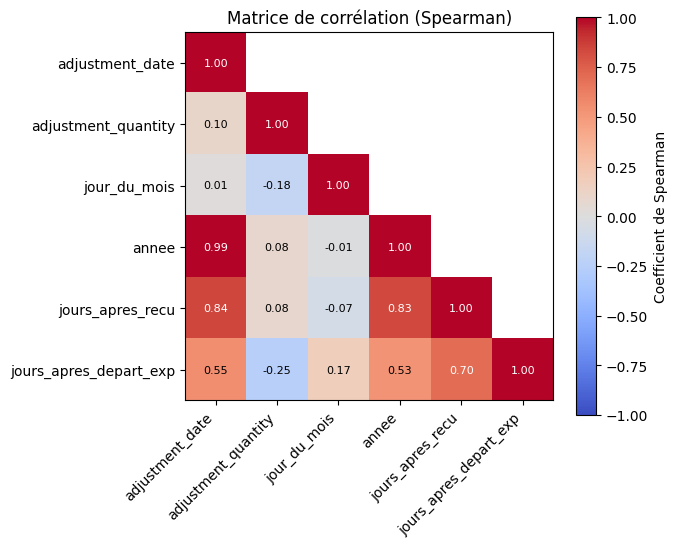


Paires avec |spearman| >= 0.7 :
            variable_1       variable_2   valeur
                 annee  adjustment_date 0.993077
      jours_apres_recu  adjustment_date 0.841897
      jours_apres_recu            annee 0.830060
jours_apres_depart_exp jours_apres_recu 0.700000
Variables catégorielles utilisées (12) : ['facility_code', 'item_category', 'unit', 'adjustment_reason', 'approved_by_role', 'related_receipt_number', 'adjustment_status', 'sens', 'fin_de_mois', 'a_recu', 'a_expedition', 'coherence_lien']
Variables exclues : ['adjustment_number (identifiant)', 'adjustment_date (date)', 'adjustment_quantity (numérique)', 'related_shipment_number (38 modalités)', 'jour_du_mois (numérique)', 'annee (numérique)', 'jours_apres_recu (numérique)', 'jours_apres_depart_exp (numérique)']


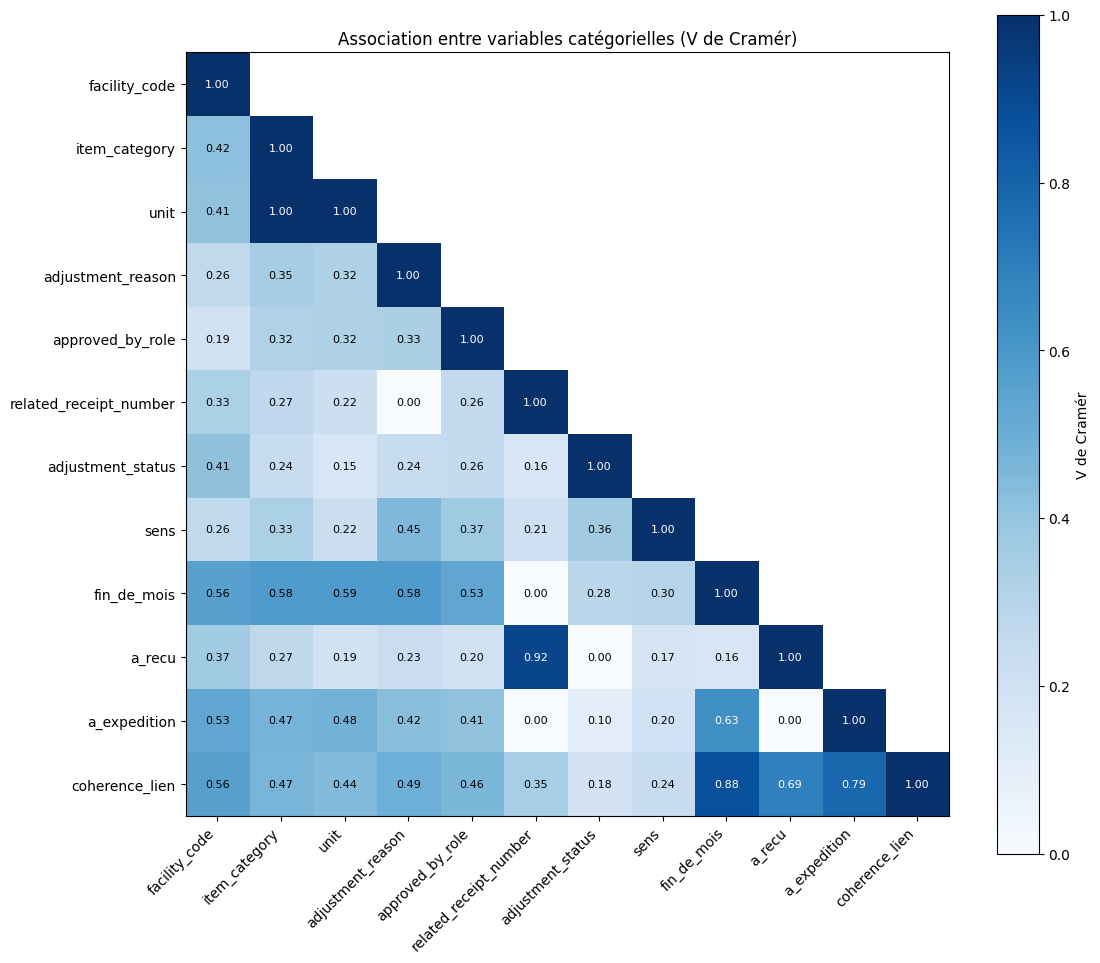


Paires avec |V de Cramér| >= 0.5 :
    variable_1             variable_2   valeur
          unit          item_category 0.996317
        a_recu related_receipt_number 0.916831
coherence_lien            fin_de_mois 0.876377
coherence_lien           a_expedition 0.785996
coherence_lien                 a_recu 0.689849
  a_expedition            fin_de_mois 0.631441
   fin_de_mois                   unit 0.585497
   fin_de_mois      adjustment_reason 0.584344
   fin_de_mois          item_category 0.580770
coherence_lien          facility_code 0.561181
   fin_de_mois          facility_code 0.556339
   fin_de_mois       approved_by_role 0.534916
  a_expedition          facility_code 0.532967


In [7]:
resultats = tracer_matrices(adj)

### Rapport d'analyse — associations

**Résultats**
- **Spearman** (6 variables) : `année` – `date` = **0,99** (trivial), `jours_apres_recu` – `date` = **0,84** et – `année` = 0,83, `jours_apres_depart_exp` – `jours_apres_recu` = 0,70. La **quantité** n'est liée à presque rien : 0,10 avec la date, 0,08 avec l'année, −0,18 avec le jour du mois et **−0,25** avec le délai après le départ de l'expédition citée.
- **V de Cramér** (12 variables catégorielles ; `related_shipment_number`, 38 modalités, est exclue) : `unit` – `item_category` = **1,00** ; **`fin_de_mois`** est associée à `item_category` (0,58), `unit` (0,59), `adjustment_reason` (0,58), `facility_code` (0,56) et `approved_by_role` (0,53), ainsi qu'à `a_expedition` (**0,63**) et à `coherence_lien` (**0,88**).
- Autres liens modérés : `adjustment_reason` – `sens` (0,45), `approved_by_role` – `sens` (0,37), `adjustment_reason` – `approved_by_role` (0,33), `facility_code` – `adjustment_status` (0,41) et – `item_category` (0,42).

**Interprétation**
- La **corrélation entre ancienneté et délai** (0,84) est un **artefact des références incohérentes** : les reçus et les expéditions cités ont des dates sans rapport avec la date de l'ajustement, si bien que plus l'ajustement est ancien, plus l'écart avec le document cité est négatif.
- **La quantité est quasi indépendante de tout** : la taille d'un ajustement ne dépend ni de la date, ni du moment du mois. Il n'y a pas de dérive dans le temps.
- **La date de fin de mois est une signature** : elle caractérise un sous-ensemble de lignes (catégorie, motif et approbateur particuliers, expédition citée, lien cohérent). Le V de 0,88 avec `coherence_lien` montre que **les liens cohérents sont presque tous des ajustements de fin de mois**. Cette structure est précisée à l'étape 4.
- Le **motif détermine en partie le sens** (0,45) : certains motifs ne comportent que des retraits (étape 5).
- `unit` est redondante avec `item_category` (V = 1,00).

**Points d'attention** : le V de Cramér avec `facility_code` (29 modalités sur 140 lignes) est gonflé par les petits effectifs ; les chiffres de ces paires (0,41 à 0,56) sont à lire comme des ordres de grandeur.

---
## 4. Recherche de patterns : itemsets fréquents

### 4.1 Enrichissement et extraction des itemsets


Le tableau est enrichi avec la région et la catégorie du site (`erp_facilities`). Sont exclues : `unit` (redondante), les numéros et dates (remplacés par `fin_de_mois`, `annee`, `a_recu`, `a_expedition`) et les variables numériques peu renseignées.

In [8]:
fa = lire_csv("../data/logistics/erp_facilities.csv")
adj_p = enrichir(adj, fa, cle="facility_code", cle_autre="facility_code",
                 colonnes=["region", "facility_category"], prefixe="site_")

# unit est déterminée par item_category (V = 1) ; les numéros et dates sont remplacés par des indicateurs
res = detecter_patterns(adj_p, min_support=0.03,
                        exclure=["unit", "adjustment_number", "adjustment_date", "related_receipt_number",
                                 "related_shipment_number", "jour_du_mois", "jours_apres_recu",
                                 "jours_apres_depart_exp"])
F = res["itemsets"]

Transactions : 140 | colonnes utilisées : 14 | items distincts : 85

min_support = 0.030 (support absolu >= 5) -> 34511 itemsets fréquents, dont 2299 fermés
Répartition par taille : {1: 62, 2: 770, 3: 2960, 4: 5643, 5: 7238, 6: 7200, 7: 5583, 8: 3248, 9: 1355, 10: 382, 11: 65, 12: 5}

--- Itemsets les plus FRÉQUENTS (taille >= 2) : décrivent surtout la majorité ---
                                                 itemset  support_abs  support_rel  lift
                      a_expedition=non ∧ fin_de_mois=non          102        0.729 1.155
                            a_recu=non ∧ fin_de_mois=non           97        0.693 0.967
             a_expedition=non ∧ coherence_lien=sans lien           85        0.607 1.359
                   a_recu=non ∧ coherence_lien=sans lien           85        0.607 1.197
a_expedition=non ∧ a_recu=non ∧ coherence_lien=sans lien           85        0.607 1.626
                           a_expedition=non ∧ a_recu=non           85        0.607 0.987
 a_recu=n

### 4.2 Profil du groupe le plus surprenant



In [9]:
# Profil du groupe décrit par l'itemset le plus surprenant (et non le plus fréquent)
S = res["surprenants"]
itemset = frozenset(S.itemset.iloc[0])
groupe = masque_itemset(res["transactions"], itemset, adj_p.index)
print("Itemset analysé :", " ∧ ".join(sorted(itemset)))
print("Effectif du groupe :", int(groupe.sum()), "lignes sur", len(adj_p))
profil = profiler_groupe(adj_p, groupe)
print(profil[profil.part_groupe >= 0.95][["colonne", "valeur_dominante", "part_groupe", "part_ensemble"]].to_string())

Itemset analysé : a_expedition=oui ∧ a_recu=non ∧ adjustment_status=posted ∧ coherence_lien=lien coherent ∧ fin_de_mois=oui ∧ item_category=biological_sample ∧ sens=retrait ∧ site_facility_category=transfer_hub
Effectif du groupe : 10 lignes sur 140
                   colonne   valeur_dominante  part_groupe  part_ensemble
0           coherence_lien      lien coherent          1.0       0.128571
1              fin_de_mois                oui          1.0       0.142857
2   site_facility_category       transfer_hub          1.0       0.164286
3                     unit         sealed_lot          1.0       0.257143
4            item_category  biological_sample          1.0       0.257143
5             a_expedition                oui          1.0       0.264286
9                     sens            retrait          1.0       0.635714
10       adjustment_status             posted          1.0       0.642857
12  related_receipt_number            unknown          1.0       0.835714
13        

### Rapport d'analyse — patterns

**Résultats**
- Base : **140 transactions**, 14 colonnes, **85 items**. À `min_support = 3 %` : **34 511 itemsets fréquents**, dont seulement **2 299 fermés** (taille jusqu'à 12 items, pic à 5).
- **Itemsets les plus fréquents** : `a_expedition=non ∧ fin_de_mois=non` (102 lignes, 72,9 %), `a_recu=non ∧ fin_de_mois=non` (97), `sans lien ∧ pas d'expédition ∧ pas de reçu` (85). Leurs lifts vont de 0,97 à 1,63 ; les plus élevés viennent de la **redondance entre variables dérivées** (`sans lien` découle de `a_recu` et `a_expedition`), pas d'un phénomène réel.
- **Itemsets les plus surprenants** (fermés, lift ≥ 3, support ≥ 10) : deux familles nettes.
  1. **Retraits d'échantillons biologiques en fin de mois, liés à une expédition** : `biological_sample ∧ fin_de_mois=oui ∧ a_expedition=oui ∧ lien cohérent ∧ posted ∧ retrait`. Le groupe de base compte **17 lignes** (lift ≈ 285) ; avec un site de type `transfer_hub` et le motif `transfer posting correction`, il se réduit à **10 lignes** (lift ≈ 1 000).
  2. **Retraits de consommables médicaux sur `FCL-1007` et `FCL-1010`** : `medical_consumables ∧ retrait ∧ posted ∧ sans lien ∧ quantité faible (−2,5 à 1)`, **11 à 14 lignes** par site (lift de 370 à 830).
- **Profil du groupe n° 1** (10 lignes) : identiques à 100 % sur `biological_sample`, `sealed_lot`, `fin_de_mois = oui`, site `transfer_hub`, `posted`, `retrait`, **lien cohérent** et **expédition citée** (sans reçu).

**Interprétation et réserves**
- Les deux familles sont **complémentaires** : la première concerne des échantillons biologiques, **toujours** en fin de mois, avec une référence à une expédition **cohérente** ; la seconde concerne des consommables médicaux sur deux sites précis, **sans aucune référence**.
- Dans les deux cas, les lignes sont **toutes `posted`** : aucune n'est en attente ni seulement approuvée.
- Les lifts de plusieurs centaines sont **gonflés mécaniquement** par la taille des itemsets (produit de nombreux petits supports) : ils signalent une co-occurrence quasi systématique, pas une intensité mesurable. Il faut les confronter aux autres tables : c'est l'objet du 4.3.

### 4.3 Recoupement avec les expéditions et avec l'inventaire



In [10]:
# --- A) Expéditions « wildlife » : sont-elles citées par des ajustements ?
sh["arrivee_dt"] = pd.to_datetime(sh.arrival_time.replace("unknown", np.nan), format="mixed", errors="coerce").dt.normalize()
wild = sh[sh.declared_purpose.str.contains("wildlife")]
adj["lien_wildlife"] = adj.related_shipment_number.isin(wild.shipment_number)
print(f"Expéditions wildlife : {len(wild)} | citées par au moins un ajustement : "
      f"{int(wild.shipment_number.isin(adj.related_shipment_number).sum())} | ajustements concernés : {int(adj.lien_wildlife.sum())}")
w = adj[adj.lien_wildlife]
for c in ["item_category", "sens", "adjustment_status", "fin_de_mois", "adjustment_reason", "approved_by_role"]:
    print(f"  {c:20s}", w[c].value_counts().to_dict())
print("  quantité              :", w.adjustment_quantity.describe()[["mean", "min", "max"]].round(2).to_dict())

# --- B) Chaîne « clinical » : un ajustement « programme » suit-il l'arrivée de chaque expédition clinical ?
programme = ["specialist programme issue", "controlled-area consumption", "procedure stock issue"]
adj["motif_programme"] = adj.adjustment_reason.isin(programme)
clin = sh[sh.declared_purpose.str.contains("clinical")]
suivi = []
for _, c in clin.iterrows():
    d = (adj.adjustment_date - c.arrivee_dt).dt.days
    suivi.append(int(((adj.facility_code == c.destination_facility_code) & d.between(4, 8) & adj.motif_programme).sum()))
print(f"\nAjustements « programme » : {int(adj.motif_programme.sum())} | catégories : {adj[adj.motif_programme].item_category.value_counts().to_dict()}"
      f" | sites : {adj[adj.motif_programme].facility_code.value_counts().to_dict()} | statuts : {adj[adj.motif_programme].adjustment_status.value_counts().to_dict()}")
print(f"Expéditions clinical : {len(clin)} | suivies d'un ajustement « programme » 4 à 8 jours après l'arrivée, même site : {sum(v > 0 for v in suivi)}")
autres = sh[~sh.declared_purpose.str.contains("clinical") & sh.destination_facility_code.isin(clin.destination_facility_code.unique())
            & sh.arrivee_dt.notna()]
t_autres = sum(((adj.facility_code == c.destination_facility_code) & (adj.adjustment_date - c.arrivee_dt).dt.days.between(4, 8)).any()
               for _, c in autres.iterrows())
print(f"Témoin : {len(autres)} autres expéditions vers ces sites, suivies d'un ajustement 4 à 8 jours après : {t_autres}")

# --- C) Les ajustements expliquent-ils l'écart de stock de l'inventaire ?
b = pd.read_csv("../data/logistics/inventory_month_end.csv")
for c in ["opening_stock", "received_quantity", "outgoing_quantity", "documented_internal_use", "documented_waste", "closing_stock"]:
    b[c] = b[c].astype(str).str.extract(r"^\s*(-?[\d.,]+)")[0]
inv, _ = clean_csv(b, outlier_method=None, verbose=False)
inv["ecart_stock"] = inv.closing_stock - (inv.opening_stock + inv.received_quantity - inv.outgoing_quantity
                                          - inv.documented_internal_use - inv.documented_waste)
adj["mois"] = adj.adjustment_date.dt.to_period("M").dt.to_timestamp()
agg = (adj.groupby(["facility_code", "mois", "item_category"])
          .agg(ajustement=("adjustment_quantity", "sum"), wildlife=("lien_wildlife", "any")).reset_index()
          .rename(columns={"mois": "reporting_month"}))
m = inv.merge(agg, on=["facility_code", "reporting_month", "item_category"], how="inner")
m["residu"] = m.ecart_stock - m.ajustement
print(f"\nLignes d'inventaire avec un ajustement le même mois (même site et même catégorie) : {len(m)} sur {len(inv)}")
print("Corrélation écart de stock / ajustement :", round(m[["ecart_stock", "ajustement"]].corr().iloc[0, 1], 2))
print(m.groupby("wildlife").agg(n=("ecart_stock", "size"), ecart_moyen=("ecart_stock", "mean"),
      ajustement_moyen=("ajustement", "mean"), residu_median=("residu", "median"),
      residu_abs_median=("residu", lambda s: s.abs().median())).round(2).to_string())
pertes = inv[inv.ecart_stock < -5]
cle = ["facility_code", "reporting_month", "item_category"]
couvertes = pertes.merge(agg[cle], on=cle, how="inner")
print(f"\nPertes fortes (< -5) : {len(pertes)} | avec un ajustement le même mois : {len(couvertes)} | sans aucun ajustement : {len(pertes) - len(couvertes)}")

Expéditions wildlife : 18 | citées par au moins un ajustement : 18 | ajustements concernés : 18
  item_category        {'biological_sample': 18}
  sens                 {'retrait': 18}
  adjustment_status    {'posted': 18}
  fin_de_mois          {'oui': 18}
  adjustment_reason    {'transfer posting correction': 10, 'cycle count reconciliation': 5, 'quality-hold release': 3}
  approved_by_role     {'regional operations manager': 6, 'inventory supervisor': 6, 'quality manager': 6}
  quantité              : {'mean': -2.9, 'min': -4.81, 'max': -1.08}

Ajustements « programme » : 30 | catégories : {'medical_consumables': 30} | sites : {'FCL-1010': 16, 'FCL-1007': 14} | statuts : {'posted': 30}
Expéditions clinical : 26 | suivies d'un ajustement « programme » 4 à 8 jours après l'arrivée, même site : 26
Témoin : 80 autres expéditions vers ces sites, suivies d'un ajustement 4 à 8 jours après : 4

Lignes d'inventaire avec un ajustement le même mois (même site et même catégorie) : 38 sur 500
Corr

### Rapport d'analyse — recoupement ajustements ↔ autres tables

**A. Ajustements liés aux expéditions « wildlife »**
- Les **18 expéditions « wildlife » sont toutes citées par exactement un ajustement** (18 ajustements). Ces 18 ajustements sont **tous** des `biological_sample`, **tous** des retraits (quantité moyenne **−2,90**, de −4,81 à −1,08), **tous** `posted`, **tous datés du dernier jour d'un mois**.
- Répartition des motifs : `transfer posting correction` (10), `cycle count reconciliation` (5), `quality-hold release` (3). Les approbateurs sont `regional operations manager` (6), `inventory supervisor` (6) et `quality manager` (6).
- Deux marqueurs sont **exclusifs** à ce groupe : le motif `cycle count reconciliation` (5 lignes sur 5) et le rôle `regional operations manager` (6 lignes sur 6).

**B. Ajustements « programme » et expéditions « clinical »**
- Les **30 ajustements « programme »** sont **tous** des `medical_consumables`, **tous** `posted`, **tous** des retraits, et ne portent que sur deux sites : `FCL-1010` (16) et `FCL-1007` (14), qui sont précisément les deux sites de destination des expéditions « clinical » (voir les notebooks précédents).
- **Chacune des 26 expéditions « clinical » est suivie d'un ajustement « programme » 4 à 8 jours après son arrivée, sur le même site (26 sur 26).** À titre de témoin, seules **4 des 80** autres expéditions arrivées sur ces deux sites sont suivies d'un ajustement dans la même fenêtre.
- Les 4 ajustements « programme » restants ne suivent pas de telle expédition.

**C. Ajustements et écart de stock de l'inventaire**
- **38 lignes d'inventaire sur 500** ont un ajustement le même mois, pour le même site et la même catégorie ; la corrélation entre écart de stock et ajustement est de **0,69**.
- **Pour les 20 lignes sans lien avec une expédition « wildlife »**, l'ajustement **reproduit l'écart** : écart moyen +0,84, ajustement moyen +1,36, résidu médian −0,54 (|résidu| médian 1,17). Les ajustements ordinaires jouent bien leur rôle de **régularisation du stock**.
- **Pour les 18 lignes liées à une expédition « wildlife »**, l'écart moyen est de **−7,28** mais l'ajustement moyen de **−2,90** : les ajustements ne couvrent qu'environ **40 %** du manque, avec un résidu médian de **−3,69** (|résidu| médian 4,44).
- Sur les 28 pertes fortes de l'inventaire (écart < −5), **11 ont un ajustement le même mois et 17 n'en ont aucun**.

**Interprétation**
- Il existe **trois populations d'ajustements** : (1) les **ajustements ordinaires** (92 lignes), aux signes mélangés, de statuts variés, qui corrigent l'inventaire ; (2) les **ajustements « programme »** (30), liés mécaniquement aux livraisons cliniques ; (3) les **ajustements « wildlife »** (18), liés mécaniquement aux expéditions du même nom, en fin de mois, et qui ne couvrent qu'une partie du manque constaté.
- Les populations (2) et (3) sont **plus régulières que le reste** : toutes `posted`, tous retraits, motifs et approbateurs dédiés, et (pour les « wildlife ») des références cohérentes alors que presque toutes les références des ajustements ordinaires sont incohérentes (voir le 5.3).



---
## 5. Détection d'anomalies


Seules **3 variables numériques** sont exploitables : la quantité, le jour du mois et la date (en jours). Les autres colonnes (motif, approbateur, statut…) sont catégorielles. La détection statistique est donc complétée au 5.3 par des **contrôles de cohérence**.

### 5.1 Détection globale (toutes les lignes comparées entre elles)

Variables utilisées (3) : ['adjustment_quantity', 'jour_du_mois', 'adjustment_date']

=== 1. Détection univariée (IQR) ===


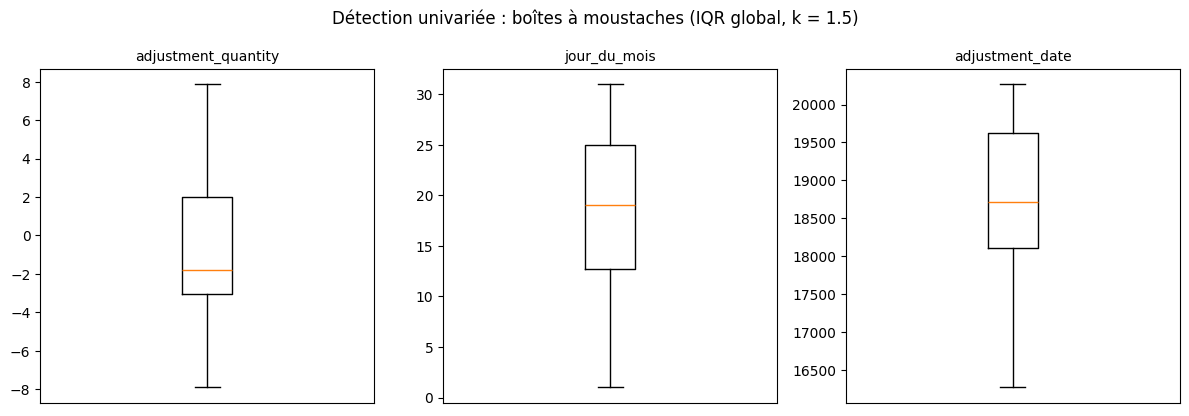

                           Q1        Q3   IQR  borne basse  borne haute  atypiques (IQR global)
variable                                                                                       
adjustment_quantity    -3.035     2.005  5.04        -10.6        9.565                       0
jour_du_mois            12.75        25 12.25       -5.625        43.38                       0
adjustment_date     1.811e+04 1.963e+04 1,518    1.583e+04     2.19e+04                       0

=== 2. Détection multivariée par regroupement ===


c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1038, 

K-means : k = 5 (silhouette 0.30), seuil de distance = 1.82 -> 2 atypiques
   (silhouette faible : peu de groupes nets ; les scores de distance restent exploitables)
DBSCAN  : eps = 1.14, min_samples = 5 -> 1 groupes, 1 points bruit

=== 3. Angle-based Outlier Detection (ABOD) ===
ABOD    : FastABOD (k = 20), 3% d'ABOF les plus bas (seuil = 0.08772) -> 5 atypiques


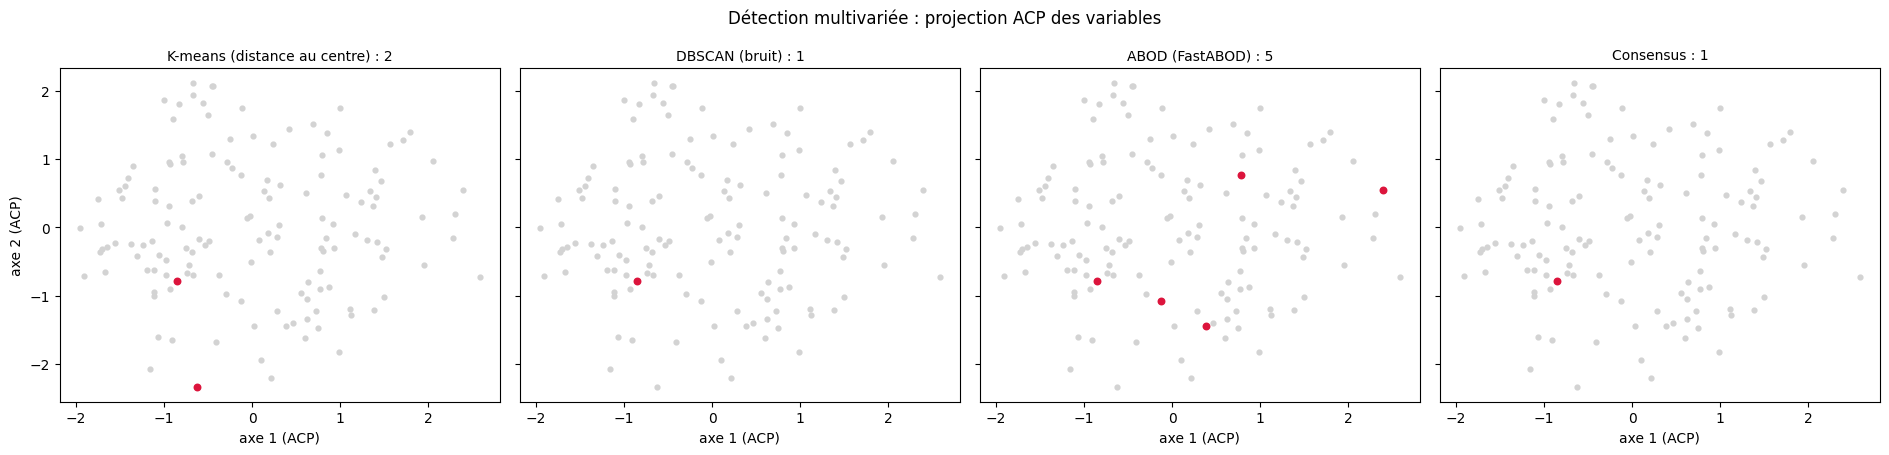


=== 4. Synthèse ===
Lignes signalées : {'out_kmeans': 2, 'out_dbscan': 1, 'out_abod': 5}
Nombre de méthodes d'accord : {0: 134, 1: 5, 3: 1}
Lignes en consensus (>= 2 méthodes) : 1
Lignes avec au moins une valeur hors IQR : 0


In [11]:
# A) Détection globale : toutes les lignes sont comparées entre elles
variables = ["adjustment_quantity", "jour_du_mois", "adjustment_date"]
resultat_global = detecter_anomalies(df=adj, colonnes=variables, inclure_dates=True,
                                     show=True, contamination=0.03, min_methodes=2)

In [12]:
cols = ["adjustment_number", "facility_code", "adjustment_date", "item_category", "adjustment_quantity",
        "adjustment_reason", "approved_by_role", "adjustment_status", "n_methodes"]
resultat_global.anomalies[cols].reset_index(drop=True)

,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,adjustment_reason,approved_by_role,adjustment_status,n_methodes
0,ADJ-2015-00003,FCL-1024,2015-10-30,monitoring_equipment,3.68,late receipt posting,warehouse manager,posted,3


### 5.2 Détection par catégorie d'article (chaque ligne comparée aux autres de sa catégorie)

*L'option `group_by` calcule l'IQR **à l'intérieur de chaque catégorie** et exprime les variables du multivarié par rapport à la médiane de la catégorie.*

Variables utilisées (3) : ['adjustment_quantity', 'jour_du_mois', 'adjustment_date']

=== 1. Détection univariée (IQR) ===


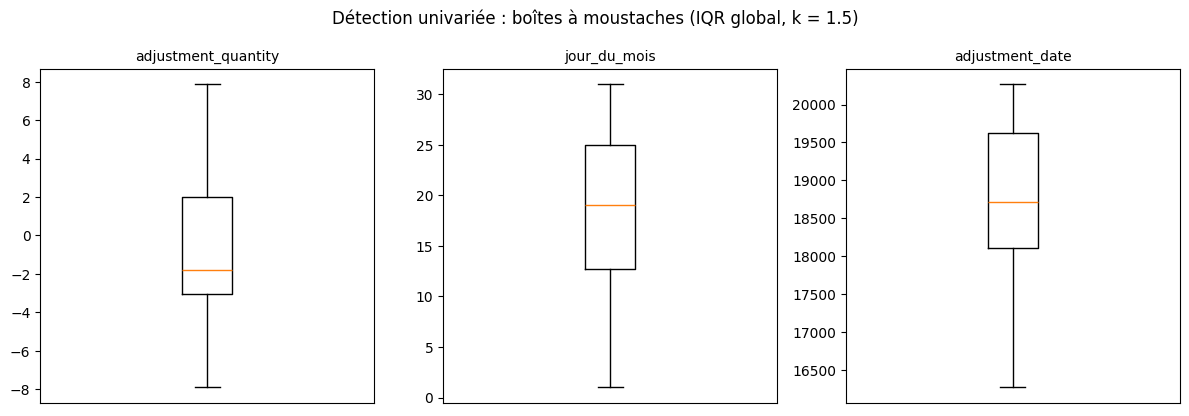

                           Q1        Q3   IQR  borne basse  borne haute  atypiques (IQR global)  atypiques (IQR par groupe)
variable                                                                                                                   
adjustment_quantity    -3.035     2.005  5.04        -10.6        9.565                       0                          15
jour_du_mois            12.75        25 12.25       -5.625        43.38                       0                           3
adjustment_date     1.811e+04 1.963e+04 1,518    1.583e+04     2.19e+04                       0                           0
Variables exprimées relativement à la médiane de leur groupe (log du ratio si > 0).

=== 2. Détection multivariée par regroupement ===
K-means : k = 8 (silhouette 0.32), seuil de distance = 1.54 -> 3 atypiques
   (silhouette faible : peu de groupes nets ; les scores de distance restent exploitables)
DBSCAN  : eps = 1.45, min_samples = 5 -> 1 groupes, 1 points bruit

=== 3. Angl

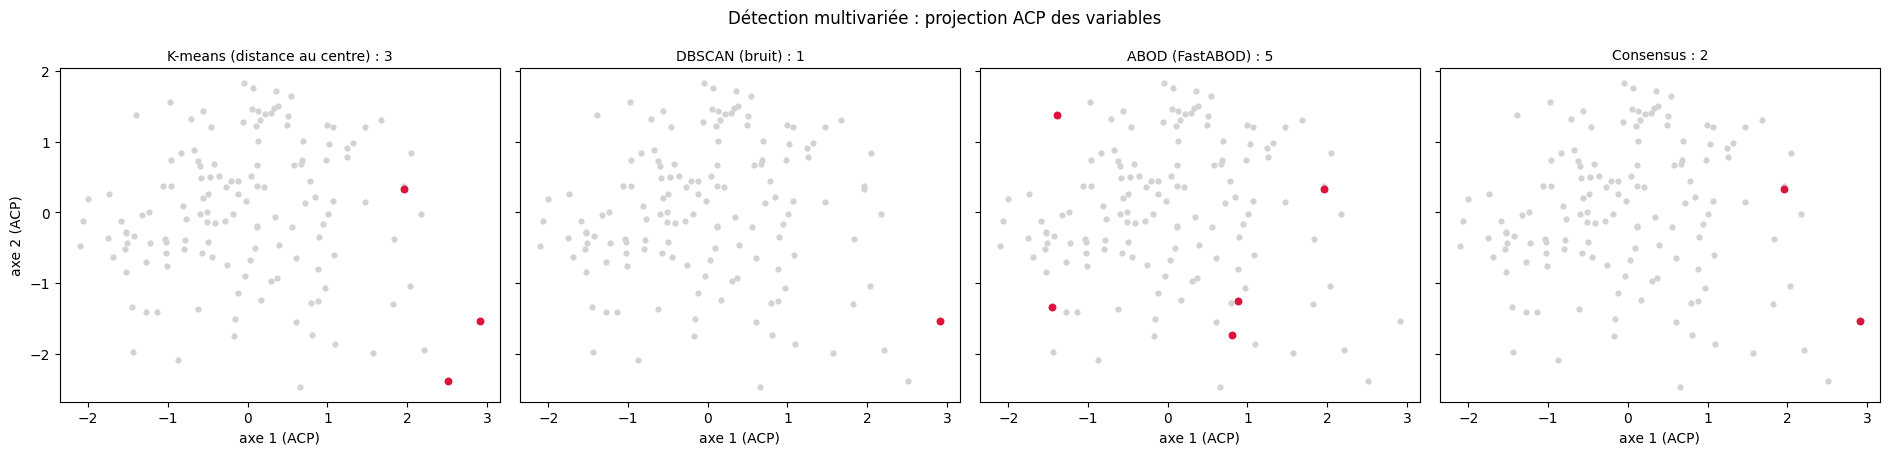


=== 4. Synthèse ===
Lignes signalées : {'out_kmeans': 3, 'out_dbscan': 1, 'out_abod': 5}
Nombre de méthodes d'accord : {0: 133, 1: 5, 2: 2}
Lignes en consensus (>= 2 méthodes) : 2
Lignes avec au moins une valeur hors IQR : 18


In [13]:
# B) Détection par catégorie d'article : chaque ligne est comparée aux autres de sa catégorie
resultat = detecter_anomalies(df=adj, colonnes=variables, group_by="item_category", inclure_dates=True,
                              show=True, contamination=0.03, min_methodes=2)

In [14]:
resultat.anomalies[cols].reset_index(drop=True)

,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,adjustment_reason,approved_by_role,adjustment_status,n_methodes
0,ADJ-2024-00113,FCL-1010,2024-03-01,medical_consumables,-1.75,specialist programme issue,quality manager,posted,2
1,ADJ-2025-00134,FCL-1027,2025-05-07,biological_sample,-1.82,cycle count correction,finance controller,pending_review,2


### 5.3 Contrôles de cohérence (règles métier)

*Les anomalies de cette table sont surtout **logiques** : on vérifie les références, les statuts, les approbateurs, le sens selon le motif et le jour du mois.*

In [15]:
# Contrôles de cohérence (règles métier) : les anomalies de cette table sont surtout logiques
print("1) Références à un document cité :")
print(pd.crosstab(adj.coherence_lien, adj.lien_wildlife, margins=True).rename(columns={False: "autres", True: "wildlife"}).to_string())

autres_liens = adj[(adj.coherence_lien != "sans lien") & ~adj.lien_wildlife]
print(f"\n   Hors wildlife : {len(autres_liens)} ajustements avec référence, dont {int((autres_liens.coherence_lien == 'lien incoherent').sum())} incohérents")
print("   Ajustement daté AVANT le reçu cité    :", int((adj.jours_apres_recu < 0).sum()), "sur", int(adj.jours_apres_recu.notna().sum()))
print("   Ajustement daté AVANT le départ cité  :", int((adj.jours_apres_depart_exp < 0).sum()), "sur", int(adj.jours_apres_depart_exp.notna().sum()))
print("   Wildlife incohérent :", adj.loc[adj.lien_wildlife & (adj.coherence_lien == "lien incoherent"),
      ["adjustment_number", "adjustment_date", "jours_apres_depart_exp"]].astype(str).values.tolist())

print("\n2) Statuts et approbateurs :")
print(pd.crosstab(adj.adjustment_status, adj.motif_programme | adj.lien_wildlife,
                  margins=True).rename(columns={False: "ajustements ordinaires", True: "programme / wildlife"}).to_string())
print("   Approbateur manquant :", adj.loc[adj.approved_by_role == "unknown", "adjustment_number"].tolist())
print("   Ajustements en attente depuis plus d'un an :", int((age > 365).sum()), "sur", len(age))

print("\n3) Signe et motif :")
print(adj.groupby("adjustment_reason").adjustment_quantity.agg(n="count", moyenne="mean", part_retraits=lambda s: (s < 0).mean())
      .round(2).sort_values("moyenne").to_string())

print("\n4) Ajustements en fin de mois :", int((adj.fin_de_mois == "oui").sum()), "dont wildlife :",
      int(((adj.fin_de_mois == "oui") & adj.lien_wildlife).sum()))

1) Références à un document cité :
lien_wildlife    autres  wildlife  All
coherence_lien                        
lien coherent         1        17   18
lien incoherent      36         1   37
sans lien            85         0   85
All                 122        18  140

   Hors wildlife : 37 ajustements avec référence, dont 36 incohérents
   Ajustement daté AVANT le reçu cité    : 11 sur 23
   Ajustement daté AVANT le départ cité  : 14 sur 37
   Wildlife incohérent : [['ADJ-2024-00121', '2024-05-31', '-1.0']]

2) Statuts et approbateurs :
col_0              ajustements ordinaires  programme / wildlife  All
adjustment_status                                                   
approved                               25                     0   25
pending_review                         25                     0   25
posted                                 42                    48   90
All                                    92                    48  140
   Approbateur manquant : ['ADJ-2024-00120

### Rapport d'analyse — anomalies

**1. Détection globale (5.1)**
- IQR : **aucune** valeur atypique (quantité : bornes −10,6 et 9,57 ; jour du mois : bornes −5,6 et 43,4 ; date : aucune).
- Multivarié : K-means k = 5 (silhouette **0,30**, groupes peu nets) → 2 atypiques ; DBSCAN (ε = 1,14, un seul groupe) → 1 point « bruit » ; ABOD (k = 20) → 5, nombre fixé par la contamination (3 % de 140).
- Accord : aucune méthode 134 lignes, une 5, deux 0, trois **1**. **Une seule ligne en consensus** : `ADJ-2015-00003` (`FCL-1024`, 30 octobre 2015, `monitoring_equipment`, **+3,68**, `late receipt posting`, `warehouse manager`, `posted`). Elle est ancienne et isolée dans le temps ; elle cite un reçu daté d'août 2022 (presque 7 ans plus tard), ce qui est confirmé par le contrôle suivant.

**2. Détection par catégorie (5.2)**
- IQR par catégorie : **15** quantités et 3 jours du mois atypiques. Multivarié : K-means k = 8 (silhouette 0,32) → 3, DBSCAN → 1, ABOD → 5.
- Accord : aucune 133, une 5, deux **2**. Les 2 lignes en consensus sont `ADJ-2024-00113` (`FCL-1010`, 1ᵉʳ mars 2024, `medical_consumables`, −1,75, `specialist programme issue`, `quality manager`, `posted`) et `ADJ-2025-00134` (`FCL-1027`, 7 mai 2025, `biological_sample`, −1,82, `cycle count correction`, `finance controller`, `pending_review`).
- **Lecture** : ces lignes ne sont pas « aberrantes » (quantités modestes). La première appartient à la famille « programme » de l'étape 4 ; la seconde est une revue en attente. **Les méthodes statistiques ne trouvent presque rien** : les variables numériques sont symétriques, bornées (±8) et indépendantes de la date. Elles ne sont pas le bon outil sur cette table.

**3. Contrôles de cohérence (5.3)**
- **Références** : sur les 55 ajustements qui citent un document, 18 sont cohérents (17 « wildlife » + 1 autre) et 37 incohérents. **Hors « wildlife », 36 des 37 ajustements avec référence sont incohérents (97 %)**. **11 des 23** ajustements citant un reçu sont **datés avant ce reçu** (jusqu'à environ 8 ans avant), et **14 des 37** citant une expédition sont datés avant son départ. La seule référence « wildlife » incohérente est `ADJ-2024-00121`, datée du 31 mai 2024, soit **un jour avant le départ** de l'expédition citée.
- **Statuts** : les **48** ajustements « programme » et « wildlife » sont **tous `posted`** ; parmi les **92** ajustements ordinaires, 42 sont `posted`, 25 `approved` et **25 `pending_review`**. **22 des 25** revues en attente ont plus d'un an. Un seul ajustement n'a pas d'approbateur (`ADJ-2024-00120`, `posted`, qui cite en outre un reçu de 2020 pour un ajustement de 2024).
- **Sens selon le motif** : quatre motifs ne comportent que des **retraits** (100 %) : `cycle count reconciliation` (5, −3,24 en moyenne), `procedure stock issue` (10, −2,24), `specialist programme issue` (11, −2,15) et `controlled-area consumption` (9, −1,87). Ce sont exactement les motifs des familles « wildlife » et « programme ». Les motifs ordinaires sont mélangés (de 44 % à 67 % de retraits), sauf `late receipt posting`, qui est à **89 % en ajouts** (+4,11 en moyenne).
- **Fin de mois** : **20 ajustements** sont datés du dernier jour du mois, dont **18 « wildlife »** (la totalité).

**Interprétation**
- Les vraies anomalies de cette table ne sont pas des **valeurs extrêmes** mais des **incohérences** : des références fausses dans presque tous les ajustements ordinaires, des revues oubliées pendant des années, et à l'inverse des flux **trop réguliers** (toujours validés, toujours en retrait, motifs et approbateurs dédiés, fin de mois, lien exact avec une expédition).
- Cette inversion est remarquable : les ajustements **liés aux flux sensibles** sont les mieux documentés (références cohérentes, aucun en attente), les ajustements **ordinaires** les moins fiables.



---
## 6. Analyse temporelle des ajustements 

Cette section étudie l'évolution des ajustements par mois et par famille.
Les familles `wildlife` et `programme` reprennent les indicateurs construits
dans les sections précédentes. Les autres lignes sont classées comme ordinaires.

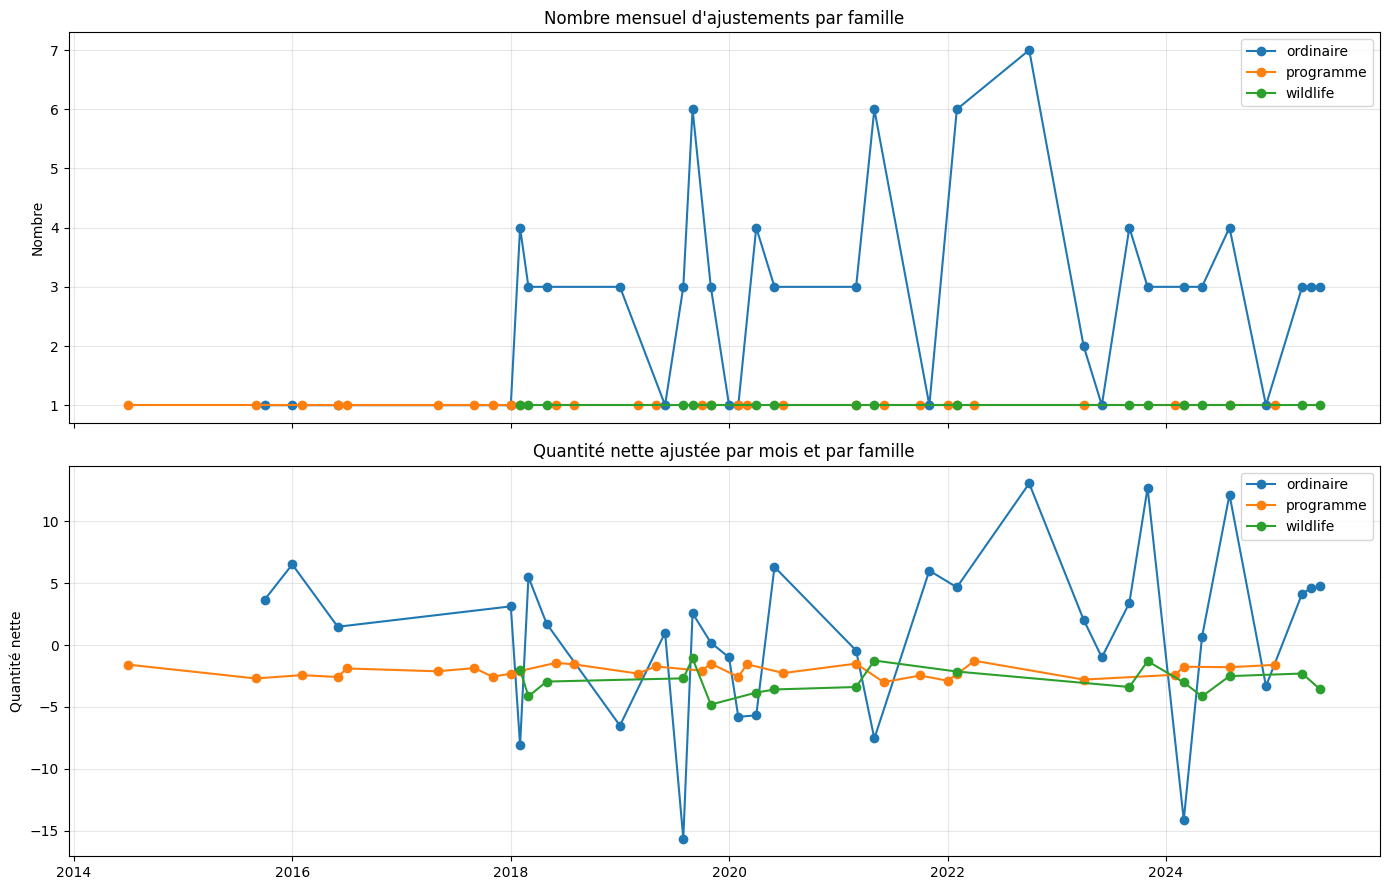

famille,ordinaire,programme,wildlife
mois,,,
2023-06-01,1.0,0.0,0.0
2023-09-01,4.0,0.0,1.0
2023-11-01,3.0,0.0,1.0
2024-02-01,0.0,1.0,0.0
2024-03-01,3.0,1.0,1.0
2024-05-01,3.0,0.0,1.0
2024-08-01,4.0,1.0,1.0
2024-12-01,1.0,0.0,0.0
2025-01-01,0.0,1.0,0.0


In [16]:
# Préparation d'une copie de travail : les données adj et les indicateurs existants sont conservés.
adj_temp = adj.copy()
adj_temp["adjustment_date"] = pd.to_datetime(adj_temp["adjustment_date"], errors="coerce")
adj_temp = adj_temp.dropna(subset=["adjustment_date"]).copy()

# Les indicateurs lien_wildlife et motif_programme sont créés dans la section 4.3.
adj_temp["famille"] = np.select(
    [adj_temp["lien_wildlife"].fillna(False),
     adj_temp["motif_programme"].fillna(False)],
    ["wildlife", "programme"],
    default="ordinaire"
)
adj_temp["mois"] = adj_temp["adjustment_date"].dt.to_period("M").dt.to_timestamp()

mensuel_adj = (
    adj_temp.groupby(["mois", "famille"])
    .agg(nb_ajustements=("adjustment_number", "size"),
         quantite_nette=("adjustment_quantity", "sum"))
    .reset_index()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for famille, g in mensuel_adj.groupby("famille"):
    axes[0].plot(g["mois"], g["nb_ajustements"], marker="o", label=famille)
    axes[1].plot(g["mois"], g["quantite_nette"], marker="o", label=famille)

axes[0].set_title("Nombre mensuel d'ajustements par famille")
axes[0].set_ylabel("Nombre")
axes[1].set_title("Quantité nette ajustée par mois et par famille")
axes[1].set_ylabel("Quantité nette")
for ax in axes:
    ax.grid(alpha=.3)
    ax.legend()
plt.tight_layout()
plt.show()

display(mensuel_adj.pivot(index="mois", columns="famille",
                          values="nb_ajustements").fillna(0).tail(12))

### 6.1 Autocorrélation des ajustements

L'ACF mesure la corrélation entre une série et ses versions décalées.
Les ajustements sont agrégés par mois ; les mois sans ajustement sont ajoutés
avec une valeur nulle. Les retards sont donc interprétés en mois.

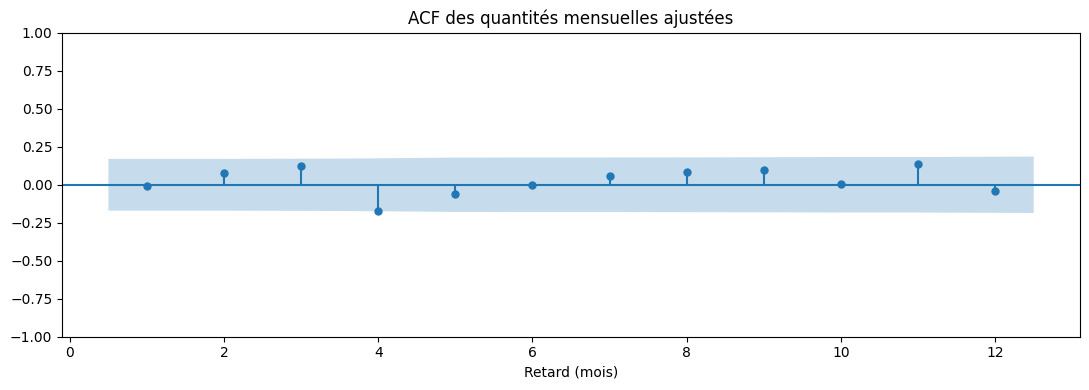

In [18]:
from statsmodels.graphics.tsaplots import plot_acf

serie_adj = (adj_temp.groupby("mois")["adjustment_quantity"].sum()
             .sort_index())
if not serie_adj.empty:
    serie_adj = serie_adj.asfreq("MS", fill_value=0)
    if len(serie_adj) >= 4 and serie_adj.nunique() > 1:
        fig, ax = plt.subplots(figsize=(11, 4))
        plot_acf(serie_adj, lags=min(12, len(serie_adj)-1),
                 zero=False, ax=ax)
        ax.set_title("ACF des quantités mensuelles ajustées")
        ax.set_xlabel("Retard (mois)")
        plt.tight_layout()
        plt.show()
    else:
        print("Série trop courte ou constante : ACF non interprétable.")
else:
    print("Aucune date valide pour construire la série temporelle.")

## 7. Analyse textuelle des motifs 

Les motifs d'ajustement sont traités comme un corpus. TF-IDF met en évidence
les termes discriminants ; les bigrammes permettent de conserver une partie
du contexte. Les résultats restent exploratoires, surtout si les motifs
sont courts ou très répétitifs.

,terme,score_tfidf
5,correction,17.189810
22,posting,13.028780
6,count,12.245889
9,cycle,12.245889
10,cycle count,12.245889
40,transfer posting,11.485226
23,posting correction,11.485226
39,transfer,11.485226
7,count correction,11.267967
13,hold,9.391486


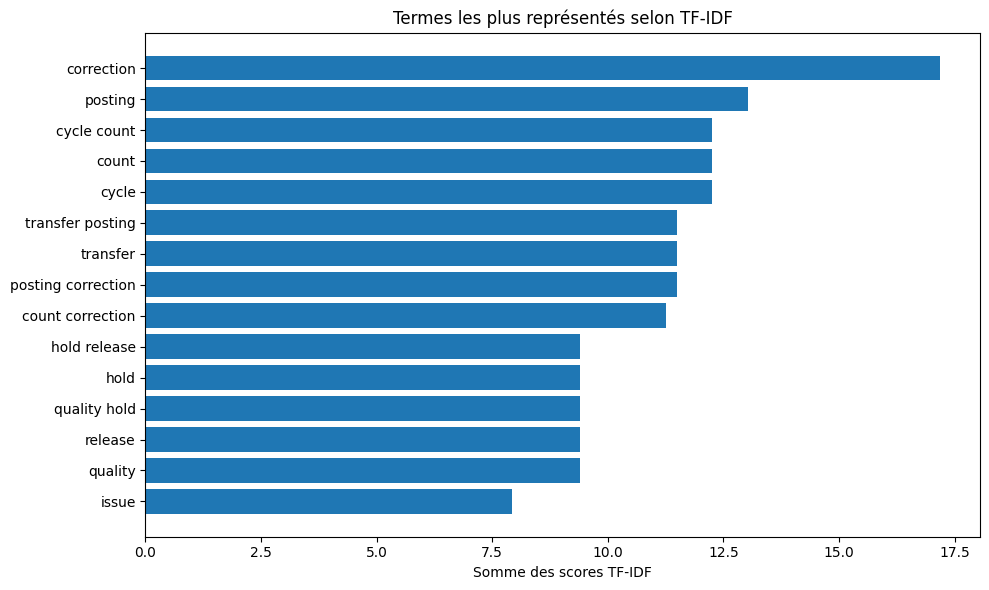

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

textes_adj = adj["adjustment_reason"].fillna("").astype(str)
tfidf_adj_vectorizer = TfidfVectorizer(
    lowercase=True, stop_words="english",
    ngram_range=(1, 2), min_df=2
)
try:
    X_adj_tfidf = tfidf_adj_vectorizer.fit_transform(textes_adj)
    scores = np.asarray(X_adj_tfidf.sum(axis=0)).ravel()
    termes = tfidf_adj_vectorizer.get_feature_names_out()
    top_adj = (pd.DataFrame({"terme": termes, "score_tfidf": scores})
               .sort_values("score_tfidf", ascending=False))
    display(top_adj.head(20))

    top_plot = top_adj.head(15).sort_values("score_tfidf")
    plt.figure(figsize=(10, 6))
    plt.barh(top_plot["terme"], top_plot["score_tfidf"])
    plt.title("Termes les plus représentés selon TF-IDF")
    plt.xlabel("Somme des scores TF-IDF")
    plt.tight_layout()
    plt.show()
except ValueError as e:
    print("TF-IDF non calculable sur ce corpus :", e)

### 7.1 Topic modeling (LDA) — exploration facultative

LDA recherche des thèmes latents à partir d'une matrice de comptage.
Avec des motifs très courts ou un vocabulaire limité, les topics peuvent
être instables : ils doivent être interprétés à partir des mots affichés
et comparés aux familles déjà connues, sans leur donner automatiquement
un sens métier.

In [20]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

cv_adj = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
try:
    X_adj_count = cv_adj.fit_transform(textes_adj)
    if X_adj_count.shape[0] >= 10 and X_adj_count.shape[1] >= 3:
        lda_adj = LatentDirichletAllocation(
            n_components=min(3, X_adj_count.shape[1]),
            random_state=42, max_iter=20
        )
        distrib_adj = lda_adj.fit_transform(X_adj_count)
        vocab_adj = cv_adj.get_feature_names_out()
        for k, composante in enumerate(lda_adj.components_):
            ids = composante.argsort()[-8:][::-1]
            print(f"Topic {k+1} : " + ", ".join(vocab_adj[ids]))
        adj_topics = adj.copy()
        adj_topics["topic_lda"] = distrib_adj.argmax(axis=1)
        adj_topics["famille"] = np.select(
            [adj_topics["lien_wildlife"].fillna(False),
             adj_topics["motif_programme"].fillna(False)],
            ["wildlife", "programme"], default="ordinaire"
        )
        display(pd.crosstab(adj_topics["topic_lda"], adj_topics["famille"],
                            normalize="index").round(2))
    else:
        print("Corpus trop petit ou vocabulaire trop réduit pour LDA.")
except ValueError as e:
    print("LDA non calculable sur ce corpus :", e)

Topic 1 : posting, correction, transfer posting, transfer, posting correction, receipt posting, late receipt, late
Topic 2 : count, cycle, cycle count, count correction, correction, quality hold, quality, hold release
Topic 3 : write, damaged, packaging, packaging write, damaged packaging, unit measure, measure, measure review


famille,ordinaire,programme,wildlife
topic_lda,,,
0,0.55,0.21,0.24
1,0.59,0.30,0.11
2,1.00,0.00,0.00


## Synthèse — Des régularisations différentes selon les circuits

L'analyse des ajustements révèle trois populations distinctes : les ajustements ordinaires, les ajustements associés au programme clinique et les ajustements associés au flux wildlife.

Les **30 ajustements du programme clinique** concernent exclusivement des consommables médicaux. Ils sont tous enregistrés comme `posted` et correspondent aux sites `FCL-1010` et `FCL-1007`. Le rapprochement temporel montre que 26 des 26 expéditions cliniques sont suivies d'un ajustement sur le même site, entre 4 et 8 jours après leur arrivée.

Les **18 ajustements wildlife** présentent une régularité encore plus marquée :
- Ils concernent tous des échantillons biologiques.
- Ils correspondent tous à des retraits.
- Ils sont tous au statut `posted`.
- Ils sont tous datés du dernier jour du mois.
- Ils sont associés aux 18 expéditions wildlife.

À l'inverse, les 92 ajustements ordinaires présentent davantage d'irrégularités. Parmi les 55 ajustements qui citent un reçu ou une expédition, 37 références sont incohérentes. De plus, 25 ajustements ordinaires sont toujours en attente de revue, avec un âge médian de 1 507 jours.

Le rapprochement avec l'inventaire met en évidence une différence supplémentaire. Pour les ajustements ordinaires associés à l'inventaire, les quantités ajustées reproduisent globalement les écarts constatés. Pour les 18 lignes wildlife, l'ajustement moyen est de −2,90 unités alors que l'écart moyen de stock atteint −7,28 unités.

Les ajustements wildlife semblent donc suivre une procédure très régulière, mais ils ne suffisent pas à expliquer les déficits observés dans les stocks.

**Indice pour l'hypothèse globale :** les ajustements confirment l'existence de deux circuits spécialisés et montrent que les opérations wildlife sont systématiquement régularisées en fin de mois. Toutefois, la régularisation ne couvre qu'une partie du déficit constaté dans l'inventaire.

**Limite :** la régularité des ajustements peut correspondre à une procédure administrative normale. Il faut la confronter aux documents de réception, aux mouvements physiques et aux règles de gestion des stocks avant de parler d'anomalie.